<a href="https://colab.research.google.com/github/owlmt/QML/blob/main/23_Adversarial_Attacks_Against_QML/VQC_AdversarialGradientCircuit_Yan2022.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Building adversarial examples for a variational quantum classifier with a gradient *circuit* (Yan et al.): step by step

This notebook re-implements, runs and checks the experiment of

> Jinge Yan, Lili Yan and Shibin Zhang, "A new method of constructing adversarial examples for quantum variational circuits",
> *Chinese Physics B* **32**, 070304 (2023) (received June 2022; manuscript online October 2022). https://doi.org/10.1088/1674-1056/ac9b32

**What it does.** A variational quantum classifier (VQC) reads an MNIST image (digits 0 and 1) through *amplitude encoding* on 8 qubits and returns the expectation value of Pauli-Z on one qubit.
To attack it, an adversary needs the gradient of the loss with respect to the *input* `x`. Earlier work computed it by automatic differentiation on a classical computer. The paper proposes to measure each gradient component
on a quantum computer: one ancilla qubit, a controlled amplitude encoding, a controlled "derivative state" `|e_i>`, the trained circuit `U(theta)`, a controlled Pauli-Z and a Hadamard; the ancilla expectation value is (up to a factor) the gradient component.
The notebook (i) trains the classifier exactly as described, (ii) builds the paper's gradient circuit gate by gate in PennyLane and checks it against the exact gradient, (iii) turns the gradient into adversarial examples,
(iv) repeats the adversarial-training experiment (Fig. 7 and Fig. 8), and (v) adds what the paper does not do: a comparison with FGSM and PGD **at equal perturbation size**, a random-perturbation control,
two classical baselines attacked with the same budget, a finite-difference comparison at equal shot budget, and a "continue training on clean data" control for the adversarial-training claim.

**How to run.** Open in Colab, choose a **CPU** runtime, then *Runtime -> Run all*. `FAST_MODE = True` (configuration cell) is a class demo of a few minutes; `FAST_MODE = False` uses the larger budgets listed in the configuration cell
(5 seeds instead of 3, more gate-level circuits, a longer PGD). **The committed outputs are from the full run (`FAST_MODE = False`, 5 seeds): 87 minutes on one thread of a CPU shared with many other jobs; the FAST run (3 seeds) took 45 minutes on the same busy machine, expect roughly a third of that on an idle laptop (estimate, not measured).** Everything is simulated exactly on a CPU: no quantum hardware and no account are needed (`IBM_TOKEN` stays empty).

**What you get at the end.** Real MNIST visualisations, drawings of the circuits that are executed, the gradient-circuit verification, the Fig. 3/7/8 analogues, the attack comparison and a claim-by-claim verdict table.

## The paper in one page

**Problem.** Adversarial examples (tiny, targeted perturbations of the input) fool classical and quantum classifiers. Constructing them needs `grad_x L`. For a quantum variational circuit the existing method (Lu, Duan and Deng 2020) computes it by automatic differentiation on a *classical* computer.

**Model.** Input `x` (N = 256 features) is amplitude-encoded: `|phi(x)> = sum_i x_i |i>` on n = log2 N = 8 qubits (for a unit vector). The circuit `U(theta)` is trained; the output is `y' = <phi|U^dag M U|phi>` with `M` = Pauli-Z on one wire, a binary classifier. Loss (Eq. 5): `L = 1/2 |y' - y|^2`.

**Gradient.** `dL/dx_i = (y' - y) kappa_i` with `kappa_i = <A|M|B> + <B|M|A>`, `|A> = U d|phi>/dx_i = U|i>`, `|B> = U|phi>` (Eq. 6). The proposed circuit (Fig. 5): `n` data qubits + 1 ancilla; H on the ancilla; the encoding `C` controlled by the ancilla; X on the ancilla, `F` (which maps `|0..0>` to `|i>`) controlled by the ancilla, X again; `U(theta)` on the data register;
`M` controlled by the ancilla (here a CZ); H on the ancilla; measure the ancilla in Z. The result is stated to equal `kappa_i` (Eq. 12), one circuit per component. Adversarial example: `x' = x + eps * grad_x L` (Eq. 2, 3), `eps` chosen per image.

**Experiment (Section 4).** MNIST digits 0 and 1; PCA from 784 to 256 features; 8 qubits; `U(theta)` of depth 10; Nesterov momentum, batch size 10, learning rate 0.05, 150 steps (Fig. 3). Four correctly classified images (two 0, two 1) are attacked (Fig. 4, 5, 6). All 0/1 images are attacked;
the distance between legitimate and adversarial image is the fidelity `|<phi(x')|phi(x)>|^2`. Adversarial examples with fidelity 0.9 are used to continue training for 150 steps (Fig. 7). Fig. 8 compares the "normal" and the "Adv." model on adversarial examples of fidelity 0.75 ... 0.99.

**Claims checked here.** (C1) The classifier reaches accuracy close to 1.0 (Fig. 3). (C2) Average loss falls from about 1.1 to about 0.3 (Fig. 3). (C3) The four correctly classified images are misclassified after the attack (Fig. 6). (C4) The ancilla measurement gives `kappa_i` (Eq. 12). (C5) Adversarial examples exist for all 0/1 images.
(C6, C7) Table 1: one measurement instead of two, fewer resources and more efficient than finite differences. (C8) Fine-tuning on fidelity-0.9 adversarial examples reaches high accuracy (Fig. 7). (C9, C10) The adversarially trained model has higher accuracy on low-fidelity adversarial examples, "which means that the model ... is more robust" (Fig. 8).
The paper reports its results only as curves (Fig. 3, 7, 8) and a table of complexities (Table 1); there are no printed accuracy numbers, so the numerical claims are read from axis ranges and text, and the verdicts say so.

### What follows the paper and what had to be chosen

| Item | Paper | This notebook |
|---|---|---|
| Data | MNIST, all images labelled 0 and 1 | identical: MNIST digits 0 and 1 from the Hugging Face mirror `ylecun/mnist` (public, 12 665 training and 2 115 test images); 2 000 training images are held out as a validation split (CHOICE) |
| Reduction to 256 features | "PCA ... from 28 x 28 = 784 to 16 x 16 = 256" | **uncentred** PCA (truncated SVD, 256 components) fitted on the training split. CHOICE: ordinary centred PCA makes the digits 0 and 1 mirror images (`x` vs `-x`) which a quadratic model cannot separate (about 79 % accuracy, ablation in section 4); the paper reports accuracy close to 1 |
| Encoding | amplitude encoding of the 256 features on 8 qubits | identical; `qml.AmplitudeEmbedding(normalize=True)`; labels coded -1 / +1 (CHOICE) |
| `U(theta)` | "depth 10" (Fig. 2, gates not specified) | `qml.StronglyEntanglingLayers` with 10 layers, 240 parameters (CHOICE); measured wire 0 (CHOICE) |
| Loss, optimiser | `1/2 |y'-y|^2`; Nesterov, batch 10, learning rate 0.05, 150 steps | identical; Nesterov momentum 0.9 (CHOICE, PennyLane default); the scale of the initial angles is chosen on the validation split from {0.01, 0.1, 1} (CHOICE) |
| Gradient circuit | Fig. 5, Eq. (7)-(12) | built gate by gate (controlled `MottonenStatePreparation` as the controlled encoding `C`, CNOTs from the ancilla as `F`, CZ as the controlled `M`); run at gate level for a subset of components and in a batched, mathematically identical form for all 256 (equality asserted) |
| Attack | `x' = x + eps grad L`, `eps` chosen per image | identical (`eps` found in closed form so that the fidelity equals a chosen target F); FGSM, PGD and a random direction at the same F are added |
| Adversarial training | continue training 150 steps on fidelity-0.9 examples | identical, on 2 000 adversarial training images crafted against the normal model; controls added: 150 extra clean steps, 50/50 mixture |
| Fig. 8 | accuracy vs fidelity for "normal" and "Adv." (which adversarial examples are shown to which model is not stated) | three readings are evaluated: examples crafted on the normal model, white-box paper attack and white-box PGD on each model itself |
| Seeds | not stated | `SEED = 42`, results over 3 (FAST) or 5 seeds, mean +- std |
| Classical baselines | none | MLP (256-16-1, tanh, same loss/optimiser/steps) and logistic regression on the same unit vectors, attacked with the same budget |

## 0. Setup

In [1]:
# Versions tested with this notebook (October 2026). Colab already ships numpy, pandas, scikit-learn, matplotlib and PyTorch.
# We add PennyLane (the paper's framework) and the Hugging Face client. The pip line runs on Colab (or wherever a package is missing);
# a prepared local environment is left untouched.
import importlib.util
IN_COLAB = importlib.util.find_spec("google.colab") is not None
missing = [m for m in ("pennylane", "huggingface_hub", "pyarrow", "PIL", "torch") if importlib.util.find_spec(m) is None]
if IN_COLAB or missing:
    %pip install -q "pennylane==0.45.1" huggingface_hub pyarrow pillow
    print("Packages installed. If Colab asks you to restart the session, do so and run all cells again.")
else:
    print("All packages present; skipping pip install.")


All packages present; skipping pip install.


In [2]:
# ---------------- configuration: every tunable constant lives here ----------------
FAST_MODE = False      # True: class demo (a few minutes). False: the full budget documented below.

SEED        = 42                       # CHOICE: the paper gives no seed
N_SEEDS     = 3 if FAST_MODE else 5    # independent training runs (seeds SEED, SEED+1, ...); results are reported as mean +- std
NQ          = 8                        # paper: 8 qubits (2^8 = 256 amplitudes)
N_FEAT      = 2 ** NQ                  # paper: 784 pixels -> 256 features
N_LAYERS    = 10                       # paper: "the depth of U(theta) is 10" (read as 10 layers, see the choices table)
STEPS       = 150                      # paper: 150 training steps (Fig. 3, Fig. 7)
BATCH       = 10                       # paper: batch size 10
LR          = 0.05                     # paper: learning rate 0.05
MOMENTUM    = 0.9                      # CHOICE: PennyLane's default Nesterov momentum (the paper does not state it)
INIT_GRID   = [0.01, 0.1, 1.0]         # CHOICE: candidate std of the initial rotation angles; picked on the validation split
N_VAL       = 2000                     # validation images held out of the MNIST training split (never used for fitting transforms)

F_TRAIN     = 0.9                      # paper: adversarial examples with fidelity 0.9 are used for adversarial training
FID_GRID    = [0.75, 0.81, 0.87, 0.90, 0.93, 0.96, 0.99]   # paper's Fig. 8 axis (0.75 ... 0.99) plus 0.90, 0.96
N_ADV_POOL  = 2000                     # CHOICE: number of training images turned into adversarial examples for adversarial training
PGD_STEPS   = 10 if FAST_MODE else 20  # CHOICE: PGD iterations of the comparison attack (not in the paper)

CIRC_IMAGES = 2 if FAST_MODE else 4    # images for which the *gate-level* gradient circuit is executed (2.3 s per circuit on a busy CPU)
CIRC_COMPS  = 6 if FAST_MODE else 16  # gradient components per image run at gate level (the batched exact circuit runs all 256)
N_SHOT_IMG  = 40 if FAST_MODE else 100   # images for the shot-noise comparison of the gradient estimators
SHOT_GRID   = [10 ** 2, 10 ** 3, 10 ** 4, 10 ** 5, 10 ** 6]   # CHOICE: shots per gradient component
N_SHOT_ATK  = 500 if FAST_MODE else 1000 # test images attacked with shot-noisy gradients

MLP_HIDDEN  = 16                       # CHOICE: classical baseline #1: one hidden layer of 16 tanh units (4 112 parameters), same optimiser/loss/steps
LR_C        = 100.0                    # CHOICE: classical baseline #2: logistic regression with weak regularisation (inputs are unit vectors)

IBM_TOKEN   = ""                       # not used: everything is simulated exactly, no hardware
DATA_DIR    = "data_QC312"             # cache directory for the downloaded MNIST files


In [3]:
import os, io, time, math, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

warnings.filterwarnings("ignore", category=DeprecationWarning)
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)

import torch
import pennylane as qml
from pennylane import numpy as pnp
import sklearn
from sklearn.decomposition import PCA, TruncatedSVD
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from PIL import Image

# Hugging Face token (optional: MNIST is public, not gated). If you swap in a gated data set, put your own token into Colab Secrets
# (key HF_TOKEN) or the environment variable HF_TOKEN. It is never printed or stored in the notebook.
HF_TOKEN = os.environ.get("HF_TOKEN")
if HF_TOKEN is None:
    try:
        from google.colab import userdata          # Colab: Settings > Secrets > HF_TOKEN
        HF_TOKEN = userdata.get("HF_TOKEN")
    except Exception:
        HF_TOKEN = None

torch.set_num_threads(1)                           # small tensors: more threads only add overhead on a shared machine
torch.manual_seed(SEED); np.random.seed(SEED)
rng = np.random.default_rng(SEED)
os.makedirs(DATA_DIR, exist_ok=True)
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 40); pd.set_option("display.max_rows", 200)
plt.rcParams.update({"figure.dpi": 90, "axes.grid": False})
CD = torch.complex128
T0 = time.time()
print("torch", torch.__version__, "| pennylane", qml.version(), "| scikit-learn", sklearn.__version__, "| numpy", np.__version__)
print("FAST_MODE =", FAST_MODE, "| qubits", NQ, "| layers", N_LAYERS, "| steps", STEPS, "| seeds", N_SEEDS)


torch 2.14.1+cpu | pennylane 0.45.1 | scikit-learn 1.9.1 | numpy 2.5.4
FAST_MODE = False | qubits 8 | layers 10 | steps 150 | seeds 5


## 1. Data: MNIST digits 0 and 1

MNIST is downloaded as Parquet from the Hugging Face hub (`ylecun/mnist`, public, no gate; OpenML as fallback) and cached in `DATA_DIR`. Only the digits 0 and 1 are kept (the paper's binary task). The test split of MNIST is used for all test numbers; 2 000 of the training images are held out as a validation split.

In [4]:
def load_mnist01():
    """MNIST images of the digits 0 and 1 (train and test), pixels scaled to [0, 1], as (X, y) numpy arrays."""
    out = {}
    try:
        from huggingface_hub import hf_hub_download
        for split in ("train", "test"):
            p = hf_hub_download("ylecun/mnist", f"mnist/{split}-00000-of-00001.parquet", repo_type="dataset",
                                token=HF_TOKEN or None, local_dir=os.path.join(DATA_DIR, "hf_mnist"))
            df = pd.read_parquet(p); y = df["label"].values; idx = np.flatnonzero(y <= 1)
            X = np.stack([np.array(Image.open(io.BytesIO(df["image"].iloc[i]["bytes"]))) for i in idx]).reshape(len(idx), -1)
            out[split] = (X.astype(np.float64) / 255.0, y[idx].astype(np.int64))
        src = "Hugging Face dataset ylecun/mnist (parquet)"
    except Exception as e:                                               # fallback: OpenML copy of MNIST (same 70 000 images)
        print("Hugging Face download failed (", repr(e)[:80], ") -> falling back to OpenML mnist_784")
        from sklearn.datasets import fetch_openml
        Xa, ya = fetch_openml("mnist_784", version=1, as_frame=False, return_X_y=True, data_home=DATA_DIR)
        ya = ya.astype(np.int64); Xa = Xa.astype(np.float64) / 255.0
        for split, sl in (("train", slice(0, 60000)), ("test", slice(60000, 70000))):
            m = ya[sl] <= 1; out[split] = (Xa[sl][m], ya[sl][m])
        src = "OpenML mnist_784"
    return out, src

(MN, DATA_SRC) = load_mnist01()
X_all, y_all = MN["train"]; X_te_pix, y_te = MN["test"]
# validation split taken from the training images (stratified); used for the choice of the initial-angle scale only
i_tr, i_va = train_test_split(np.arange(len(y_all)), test_size=N_VAL, stratify=y_all, random_state=SEED)
X_tr_pix, y_tr = X_all[i_tr], y_all[i_tr]; X_va_pix, y_va = X_all[i_va], y_all[i_va]
print("source:", DATA_SRC)
print(f"MNIST digits 0 and 1 -> train {X_tr_pix.shape}, validation {X_va_pix.shape}, test {X_te_pix.shape}; pixel range [{X_all.min():.0f}, {X_all.max():.0f}]")
# labels for the quantum model: Pauli-Z expectation values live in [-1, 1], so digit 0 -> -1 and digit 1 -> +1
to_pm = lambda y: 2.0 * y - 1.0
ys_tr, ys_va, ys_te = [torch.as_tensor(to_pm(y)) for y in (y_tr, y_va, y_te)]    # CHOICE: +-1 labels (the paper does not state its label coding)


mnist/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 15.6MB            

mnist/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

mnist/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 2.60MB            

mnist/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

source: Hugging Face dataset ylecun/mnist (parquet)
MNIST digits 0 and 1 -> train (10665, 784), validation (2000, 784), test (2115, 784); pixel range [0, 1]


## 2. Preprocessing: 256 features and amplitude encoding

The paper reduces 784 pixels to 256 features and amplitude-encodes them on 8 qubits (`2^8 = 256`). Amplitude encoding needs a unit vector, so each feature vector is divided by its length; the length is remembered so that an adversarial vector can be drawn as an image again.
**Everything is fitted on the training split only.** The choice between centred and uncentred PCA matters (see the code comment and the ablation in section 4).

In [5]:
# CHOICE: the paper says "PCA from 784 to 16 x 16 = 256 features". Ordinary (centred) PCA subtracts the mean image, so the digits 0 and 1 end up on opposite sides of the origin
# and a *quadratic* classifier <x|U^dag Z U|x> cannot tell x from -x. We therefore use the UNcentred PCA (truncated SVD, 256 components), fitted on the training split only.
# The centred variant is trained as an ablation in section 4 to show the difference.
svd = TruncatedSVD(n_components=N_FEAT, algorithm="randomized", random_state=SEED).fit(X_tr_pix)

def encode(X):
    """pixels -> (unit amplitude vector of 256 real numbers, original norm). Amplitude encoding needs ||x|| = 1."""
    Z = svd.transform(X); nz = np.linalg.norm(Z, axis=1, keepdims=True)
    return Z / nz, nz

A_tr, n_tr = encode(X_tr_pix); A_va, n_va = encode(X_va_pix); A_te, n_te = encode(X_te_pix)
A_tr, A_va, A_te = [torch.as_tensor(a) for a in (A_tr, A_va, A_te)]
print("explained variance of the 256 uncentred components:", round(float(svd.explained_variance_ratio_.sum()), 4))
print("amplitude vectors: shape", tuple(A_tr.shape), "| all unit length:", bool(torch.allclose(A_tr.norm(dim=1), torch.ones(len(A_tr), dtype=torch.float64))))

def to_image(unit_vec, norm):
    """back from an amplitude vector to a 28 x 28 picture (inverse SVD, clipped to [0, 1]) - used to draw adversarial images."""
    z = np.asarray(unit_vec).reshape(1, -1) * float(np.asarray(norm).reshape(-1)[0])
    return np.clip(svd.inverse_transform(z).reshape(IMG, IMG), 0, 1)


explained variance of the 256 uncentred components: 0.9912
amplitude vectors: shape (10665, 256) | all unit length: True


## Dataset Exploration and Visualisation

For the data set the notebook uses we print the shape, the feature names and the original label values with class counts, plot the real class distribution, show real images, and draw a 2-D scatter of **real observations coloured by their ground-truth label**
(PCA fitted on the training split only; the second and third panels show the exact amplitude vectors that enter the circuit). The classifier uses *amplitude* encoding, so there is no [0, pi] angle scaling; MNIST has only the two kept classes here, so there are no attack families.

=== MNIST, digits 0 and 1 ===
  train     : array shape (10665, 784) (images of 28 x 28); original label values [0, 1]; class counts {0: 4988, 1: 5677}
  validation: array shape (2000, 784) (images of 28 x 28); original label values [0, 1]; class counts {0: 935, 1: 1065}
  test      : array shape (2115, 784) (images of 28 x 28); original label values [0, 1]; class counts {0: 980, 1: 1135}
  feature names: pixel_0 ... pixel_783 (grey value in [0, 1]); after preprocessing: svd_0 ... svd_255 (section 2)
  original MNIST has 10 classes; the paper keeps only the digits 0 and 1 (binary task), so there are no further attack families to colour by.


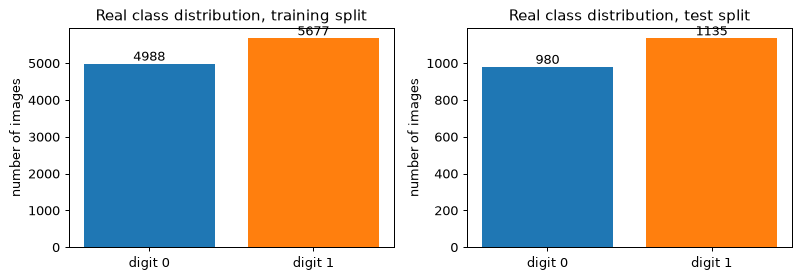

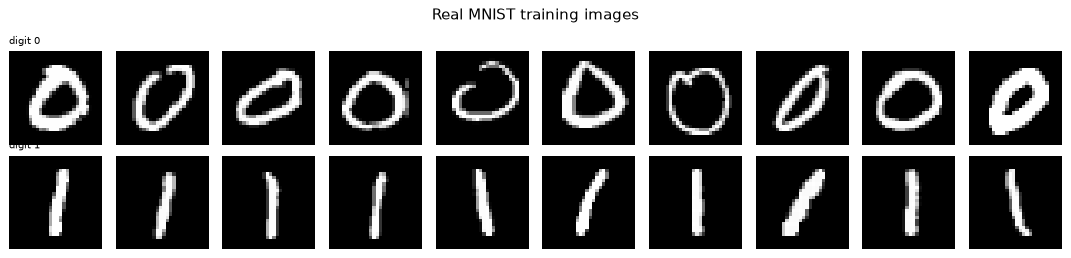

In [6]:
IMG = 28
print("=== MNIST, digits 0 and 1 ===")
for nm, X, y in [("train", X_tr_pix, y_tr), ("validation", X_va_pix, y_va), ("test", X_te_pix, y_te)]:
    print(f"  {nm:10s}: array shape {X.shape} (images of {IMG} x {IMG}); original label values {sorted(set(y.tolist()))}; class counts {dict(zip(*[a.tolist() for a in np.unique(y, return_counts=True)]))}")
print("  feature names: pixel_0 ... pixel_783 (grey value in [0, 1]); after preprocessing: svd_0 ... svd_255 (section 2)")
print("  original MNIST has 10 classes; the paper keeps only the digits 0 and 1 (binary task), so there are no further attack families to colour by.")

fig, axs = plt.subplots(1, 2, figsize=(9, 3.2))
for ax, (nm, y) in zip(axs, [("training split", y_tr), ("test split", y_te)]):
    cnt = np.bincount(y); ax.bar(["digit 0", "digit 1"], cnt, color=[plt.cm.tab10(0), plt.cm.tab10(1)])
    for k, c in enumerate(cnt): ax.text(k, c, str(c), ha="center", va="bottom")
    ax.set_title(f"Real class distribution, {nm}"); ax.set_ylabel("number of images")
plt.tight_layout(); plt.show()

fig, axs = plt.subplots(2, 10, figsize=(12, 2.9))
for r, k in enumerate((0, 1)):
    for c, i in enumerate(np.flatnonzero(y_tr == k)[:10]):
        axs[r, c].imshow(X_tr_pix[i].reshape(IMG, IMG), cmap="gray"); axs[r, c].axis("off")
    axs[r, 0].set_title(f"digit {k}", fontsize=8, loc="left")
plt.suptitle("Real MNIST training images"); plt.tight_layout(); plt.show()


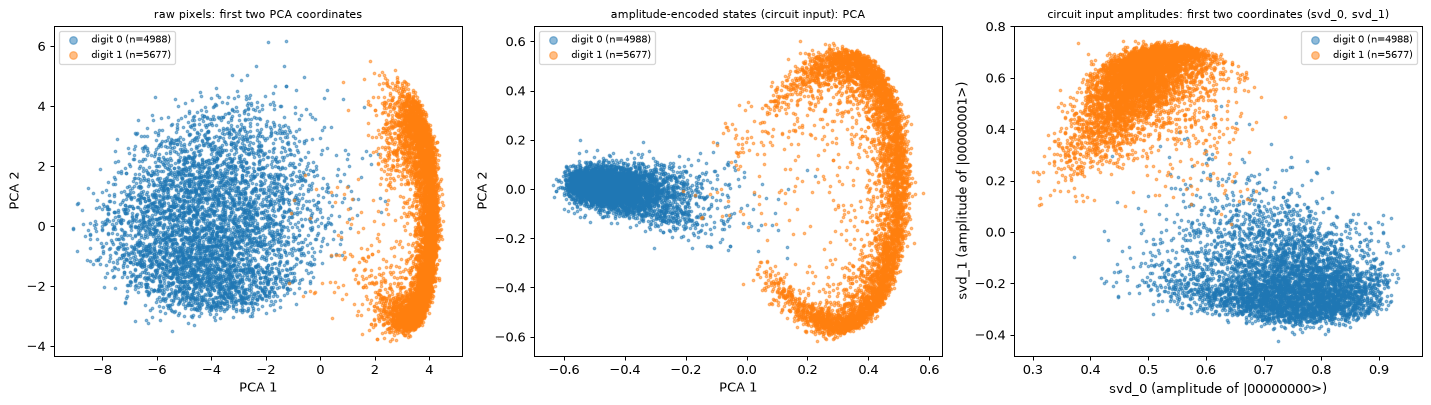

explained variance of the two PCA coordinates: pixels 0.411 | amplitude vectors 0.436


In [7]:
# 2-D scatter of the REAL observations (training split), coloured by ground-truth label. The model uses amplitude encoding, not angle encoding,
# so there is no [0, pi] angle scaling; the second and third panels show the exact vectors that enter the quantum circuit.
cols = {0: plt.cm.tab10(0), 1: plt.cm.tab10(1)}
pca2 = PCA(n_components=2, random_state=SEED).fit(X_tr_pix)                           # raw pixels, PCA fitted on the training split
Zp = pca2.transform(X_tr_pix)
pca_a = PCA(n_components=2, random_state=SEED).fit(A_tr.numpy())                      # PCA of the amplitude-encoded states
Za = pca_a.transform(A_tr.numpy())
fig, axs = plt.subplots(1, 3, figsize=(16, 4.6))
for ax, Z, ttl, xl, yl in [(axs[0], Zp, "raw pixels: first two PCA coordinates", "PCA 1", "PCA 2"),
                           (axs[1], Za, "amplitude-encoded states (circuit input): PCA", "PCA 1", "PCA 2"),
                           (axs[2], A_tr.numpy()[:, :2], "circuit input amplitudes: first two coordinates (svd_0, svd_1)", "svd_0 (amplitude of |00000000>)", "svd_1 (amplitude of |00000001>)")]:
    for k in (0, 1):
        m = y_tr == k; ax.scatter(Z[m, 0], Z[m, 1], s=4, alpha=0.5, color=cols[k], label=f"digit {k} (n={m.sum()})")
    ax.set_title(ttl, fontsize=9); ax.set_xlabel(xl); ax.set_ylabel(yl); ax.legend(markerscale=3, fontsize=8)
plt.tight_layout(); plt.show()
print("explained variance of the two PCA coordinates: pixels", round(float(pca2.explained_variance_ratio_.sum()), 3), "| amplitude vectors", round(float(pca_a.explained_variance_ratio_.sum()), 3))


## 3. The variational classifier, a fast exact simulator, and the checks that tie them together

The classifier is the PennyLane QNode `clf` below (amplitude embedding, `U(theta)`, `<Z_0>`). Training it with PennyLane's autograd takes about 1.4 s per step, i.e. minutes per training run, and the attack sweeps need millions of evaluations.
We therefore also write a **batched PyTorch state-vector simulator of the same circuit** and prove its equivalence to the QNode numerically before using it. Because the model is a quadratic form in the (unnormalised) amplitudes,
`y' = <phi|U^dag Z U|phi> = x^T W x` with the real symmetric matrix `W = Re(U^dag Z_0 U)`, all gradients of the model with respect to the input are `2 W x`; the notebook builds `W` once per trained model and asserts it against `qml.matrix`.

In [8]:
# ------------------------------------------------------------------------------------------------------------------------
# (1) The model exactly as the paper builds it, in PennyLane: AmplitudeEmbedding -> U(theta) -> <Z> on one wire.
# CHOICE: U(theta) = qml.StronglyEntanglingLayers with 10 layers (Rot on every qubit + a ring of CNOTs per layer): 10 x 8 x 3 = 240 parameters.
# CHOICE: the measured wire is wire 0.
# ------------------------------------------------------------------------------------------------------------------------
dev8 = qml.device("default.qubit", wires=NQ)

@qml.qnode(dev8, interface="autograd", diff_method="backprop")
def clf(w, x):
    qml.AmplitudeEmbedding(x, wires=range(NQ), normalize=True)       # C: |0...0> -> |phi(x)> = sum_i x_i |i>
    qml.StronglyEntanglingLayers(w, wires=range(NQ))                 # U(theta)
    return qml.expval(qml.PauliZ(0))                                  # M = Pauli-Z on one wire

# ------------------------------------------------------------------------------------------------------------------------
# (2) A batched PyTorch state-vector simulator of the SAME circuit (PennyLane convention: wire 0 is the most significant bit).
# It is used for training and for all large attack sweeps because the QNode is ~70x slower; section 3 asserts that both agree to 1e-10.
# ------------------------------------------------------------------------------------------------------------------------
def rot_mats(th):                                    # (..., 3) angles (phi, theta, omega) -> (..., 2, 2) matrices of qml.Rot = RZ(omega) RY(theta) RZ(phi)
    phi, t, om = th[..., 0], th[..., 1], th[..., 2]
    c, s = torch.cos(t / 2), torch.sin(t / 2); e = lambda a: torch.exp(1j * a)
    m00 = e(-(phi + om) / 2) * c; m01 = -e((phi - om) / 2) * s
    m10 = e(-(phi - om) / 2) * s; m11 = e((phi + om) / 2) * c
    return torch.stack([torch.stack([m00, m01], -1), torch.stack([m10, m11], -1)], -2)

def cnot_perm(pairs):                                # permutation of the 2^n basis states produced by a sequence of CNOT(control, target)
    out = np.arange(N_FEAT)
    for c, t in pairs:
        out = np.where(((out >> (NQ - 1 - c)) & 1) == 1, out ^ (1 << (NQ - 1 - t)), out)
    return torch.as_tensor(out)

# qml.StronglyEntanglingLayers uses CNOT(q, (q + r) mod n) for q = 0..n-1 with range r = (layer mod (n - 1)) + 1
PERMS = [cnot_perm([(q, (q + (l % (NQ - 1)) + 1) % NQ) for q in range(NQ)]) for l in range(N_LAYERS)]

def sim_state(w, A):
    """w: (layers, qubits, 3) angles; A: (B, 256) real unit vectors -> output states (B, 256), complex."""
    B = A.shape[0]; psi = A.to(CD); R = rot_mats(w)
    for l in range(w.shape[0]):
        t = psi.reshape((B,) + (2,) * NQ)
        for q in range(NQ):
            t = torch.movedim(torch.tensordot(R[l, q], t, dims=([1], [q + 1])), 0, q + 1)
        psi = t.reshape(B, N_FEAT); out = torch.empty_like(psi); out[:, PERMS[l]] = psi; psi = out
    return psi

ZSIGN = torch.as_tensor(np.where(((np.arange(N_FEAT) >> (NQ - 1)) & 1) == 0, 1.0, -1.0))   # eigenvalues of Z on wire 0
def sim_expval(w, A):
    return (sim_state(w, A).abs() ** 2) @ ZSIGN

def build_W(w):
    """Real symmetric 256 x 256 matrix W = Re(U^dag Z_0 U): the model output is the quadratic form <x|W|x> = x^T W x for a unit vector x."""
    U = sim_state(w, torch.eye(N_FEAT, dtype=torch.float64)).T          # column k of U is U|k>
    Wc = U.conj().T @ (ZSIGN.to(CD)[:, None] * U)
    return Wc.real.clone()

nrm = lambda X: X / X.norm(dim=-1, keepdim=True).clamp_min(1e-12)

class QModel:
    """The trained VQC as the paper's Eq. (5) sees it. fn(X) is the model on an UNnormalised vector (<phi|U^dag M U|phi> with |phi> = sum x_i |i>),
    score(X) is what the real circuit returns (AmplitudeEmbedding normalises first)."""
    name = "VQC"
    def __init__(self, w): self.w = w.detach().clone(); self.W = build_W(self.w)
    def fn(self, X): return ((X @ self.W) * X).sum(-1)
    def score(self, X): return self.fn(nrm(X))

class MLPModel:
    """Classical baseline #1: 256 -> 16 tanh -> 1 tanh, trained with the same loss, optimiser and steps as the VQC, on the same unit vectors."""
    name = "MLP"
    def __init__(self, params): self.p = [q.detach().clone() for q in params]
    def fn(self, X, p=None):
        W1, b1, W2, b2 = self.p if p is None else p
        return torch.tanh(torch.tanh(X @ W1.T + b1) @ W2.T + b2).squeeze(-1)
    def score(self, X): return self.fn(nrm(X))

class LRModel:
    """Classical baseline #2: logistic regression on the same unit vectors; score = tanh(w.x + b) so that the same loss 1/2 (score - y)^2 applies."""
    name = "LR"
    def __init__(self, w, b): self.w, self.b = torch.as_tensor(w), torch.as_tensor(b)
    def fn(self, X): return torch.tanh(X @ self.w + self.b)
    def score(self, X): return self.fn(nrm(X))

def predict(model, X): return torch.where(model.score(X) > 0, 1.0, -1.0)
def accuracy(model, X, y): return float((predict(model, X) == y).double().mean())


In [9]:
# ---------- equivalence assertions: the fast simulator IS the PennyLane circuit ----------
rg = np.random.default_rng(SEED)
w_chk = rg.normal(0, 0.7, (N_LAYERS, NQ, 3))
X_chk = rg.normal(size=(12, N_FEAT)); X_chk /= np.linalg.norm(X_chk, axis=1, keepdims=True)
a = sim_expval(torch.as_tensor(w_chk), torch.as_tensor(X_chk)).numpy()
b = np.array([clf(w_chk, x) for x in X_chk])
print("max |simulator - PennyLane QNode| over 12 random states :", np.abs(a - b).max()); assert np.allclose(a, b, atol=1e-10)
qm_chk = QModel(torch.as_tensor(w_chk))
print("max |x^T W x - QNode|                                    :", np.abs(qm_chk.fn(torch.as_tensor(X_chk)).numpy() - b).max()); assert np.allclose(qm_chk.fn(torch.as_tensor(X_chk)).numpy(), b, atol=1e-10)
U_pl = qml.matrix(qml.StronglyEntanglingLayers(w_chk, wires=range(NQ)), wire_order=range(NQ))
W_pl = np.real(U_pl.conj().T @ np.diag(ZSIGN.numpy()) @ U_pl)
print("max |W - Re(U^dag Z U) from qml.matrix|                  :", np.abs(qm_chk.W.numpy() - W_pl).max()); assert np.allclose(qm_chk.W.numpy(), W_pl, atol=1e-10)
# the model is a quadratic form, hence invariant under x -> -x (relevant for the choice of uncentred PCA in section 2)
assert torch.allclose(qm_chk.score(torch.as_tensor(X_chk)), qm_chk.score(-torch.as_tensor(X_chk)))
print("model output is invariant under x -> -x (quadratic form): OK")

def nesterov_run(params, loss_fn, sampler, steps, lr=LR, mom=MOMENTUM, monitor=None, every=5):
    """Nesterov momentum exactly as qml.NesterovMomentumOptimizer: shifted = p - mom*acc; g = grad(shifted); acc = mom*acc + lr*g; p = p - acc."""
    acc = [torch.zeros_like(p) for p in params]; hist = []
    for s in range(steps):
        batch = sampler()
        sh = [(p - mom * a_).detach().requires_grad_(True) for p, a_ in zip(params, acc)]
        grads = torch.autograd.grad(loss_fn(sh, *batch), sh)
        acc = [mom * a_ + lr * g for a_, g in zip(acc, grads)]
        params = [(p - a_).detach() for p, a_ in zip(params, acc)]
        if monitor is not None and ((s + 1) % every == 0 or s == 0): hist.append((s + 1,) + tuple(monitor(params)))
    return params, hist

q_loss = lambda sh, A, y: 0.5 * ((sim_expval(sh[0], A) - y) ** 2).mean()          # paper Eq. (5): L = 1/2 |y' - y|^2, averaged over the batch

xb, yb = torch.as_tensor(X_chk[:10]), torch.as_tensor(to_pm(rg.integers(0, 2, 10)))
w_pl = pnp.array(w_chk, requires_grad=True); opt = qml.NesterovMomentumOptimizer(LR, MOMENTUM)
for _ in range(3):
    w_pl = opt.step(lambda w_: 0.5 * pnp.mean((clf(w_, pnp.array(xb.numpy(), requires_grad=False)) - pnp.array(yb.numpy(), requires_grad=False)) ** 2), w_pl)
w_mine, _ = nesterov_run([torch.as_tensor(w_chk)], q_loss, lambda: (xb, yb), 3)
print("max |own Nesterov (torch) - qml.NesterovMomentumOptimizer (QNode)| after 3 steps:", np.abs(w_mine[0].numpy() - np.asarray(w_pl)).max()); assert np.allclose(w_mine[0].numpy(), np.asarray(w_pl), atol=1e-8)
print("OK: the simulator, the quadratic form W and the optimiser are all verified against the real PennyLane objects.")


max |simulator - PennyLane QNode| over 12 random states : 2.914335439641036e-16


max |x^T W x - QNode|                                    : 2.931682674400804e-16


max |W - Re(U^dag Z U) from qml.matrix|                  : 1.0408340855860843e-15
model output is invariant under x -> -x (quadratic form): OK


max |own Nesterov (torch) - qml.NesterovMomentumOptimizer (QNode)| after 3 steps: 2.220446049250313e-16
OK: the simulator, the quadratic form W and the optimiser are all verified against the real PennyLane objects.


## 4. Training (Fig. 3) and the classical baselines

Nesterov momentum, batch size 10, learning rate 0.05 and 150 steps as in the paper; seeds `SEED, SEED+1, ...`. The same data, loss (`1/2 |y' - y|^2`), optimiser and number of steps train a small classical network (MLP) on the same unit vectors, and logistic regression is fitted to convergence as a second classical reference.

In [10]:
def make_sampler(A, y, seed, batch=BATCH):
    r = np.random.default_rng(seed)
    def s():
        i = torch.as_tensor(r.choice(len(A), batch, replace=False)); return A[i], y[i]
    return s

def make_mixed_sampler(A1, y1, A2, y2, seed, batch=BATCH):          # half clean, half adversarial per batch
    r = np.random.default_rng(seed); h = batch // 2
    def s():
        i = torch.as_tensor(r.choice(len(A1), h, replace=False)); j = torch.as_tensor(r.choice(len(A2), batch - h, replace=False))
        return torch.cat([A1[i], A2[j]]), torch.cat([y1[i], y2[j]])
    return s

def init_w(std, seed): return torch.as_tensor(np.random.default_rng(seed).normal(0, std, (N_LAYERS, NQ, 3)))

def train_vqc(w0, sampler, steps=STEPS, monitor_set=None):
    """Nesterov training of the VQC. monitor_set=(A, y): accuracy and mean loss on that set every 5 steps (for the learning curves)."""
    mon = None
    if monitor_set is not None:
        Am, ym = monitor_set
        def mon(params):
            with torch.no_grad(): p = sim_expval(params[0], Am)
            return float((torch.where(p > 0, 1.0, -1.0) == ym).double().mean()), float(0.5 * ((p - ym) ** 2).mean())
    params, hist = nesterov_run([w0], q_loss, sampler, steps, monitor=mon)
    return params[0], hist

# ---- choose the scale of the initial angles on the validation split (CHOICE; one seed, the same data order for each candidate) ----
t = time.time(); rows = []
for std in INIT_GRID:
    w_, h_ = train_vqc(init_w(std, SEED), make_sampler(A_tr, ys_tr, SEED), monitor_set=(A_va, ys_va))
    rows.append(dict(init_std=std, val_acc=h_[-1][1], val_loss=h_[-1][2]))
init_tab = pd.DataFrame(rows); display(init_tab)
INIT_STD = float(init_tab.sort_values("val_loss").iloc[0]["init_std"])
print(f"-> initial-angle std {INIT_STD} (lowest validation loss) | {time.time() - t:.0f} s")


,init_std,val_acc,val_loss
0,0.01,0.9960,0.063498
1,0.10,0.9955,0.087298
2,1.00,0.9975,0.175042


-> initial-angle std 0.01 (lowest validation loss) | 456 s


seed 42: VQC test acc 0.9981 | MLP test acc 0.9976 | 121 s


seed 43: VQC test acc 0.9972 | MLP test acc 0.9986 | 231 s


seed 44: VQC test acc 0.9976 | MLP test acc 0.9991 | 348 s


seed 45: VQC test acc 0.9991 | MLP test acc 0.9986 | 471 s


seed 46: VQC test acc 0.9986 | MLP test acc 0.9986 | 609 s


logistic regression (lbfgs, C=100.0) test acc 0.9995


,seed,vqc_test_acc,vqc_test_loss,mlp_test_acc,mlp_test_loss
0,42,0.9981,0.0585,0.9976,0.0044
1,43,0.9972,0.0981,0.9986,0.0029
2,44,0.9976,0.0623,0.9991,0.0025
3,45,0.9991,0.0834,0.9986,0.0025
4,46,0.9986,0.0585,0.9986,0.0024


,vqc_test_acc,vqc_test_loss,mlp_test_acc,mlp_test_loss
mean,0.9981,0.0722,0.9985,0.0029
std,0.0007,0.0178,0.0005,0.0008


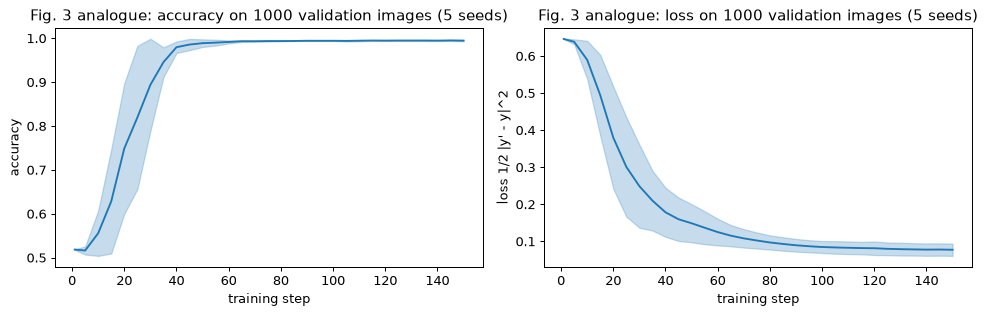

In [11]:
SEEDS = [SEED + k for k in range(N_SEEDS)]
BASE = []                                            # one dict per seed: trained VQC, its learning curve, classical baselines
mon_set = (A_va[:1000], ys_va[:1000])

def mlp_loss(sh, A, y):
    return 0.5 * ((torch.tanh(torch.tanh(A @ sh[0].T + sh[1]) @ sh[2].T + sh[3]).squeeze(-1) - y) ** 2).mean()

def init_mlp(seed, hid=MLP_HIDDEN):
    g = torch.Generator().manual_seed(seed); u = lambda shp, fan: (torch.rand(shp, generator=g, dtype=torch.float64) * 2 - 1) / math.sqrt(fan)
    return [u((hid, N_FEAT), N_FEAT), u((hid,), N_FEAT), u((1, hid), hid), u((1,), hid)]

def train_mlp(params, sampler, steps=STEPS):
    p, _ = nesterov_run(params, mlp_loss, sampler, steps); return p

t = time.time()
for s in SEEDS:
    w, hist = train_vqc(init_w(INIT_STD, s), make_sampler(A_tr, ys_tr, s), monitor_set=mon_set)
    q = QModel(w)
    mlp = MLPModel(train_mlp(init_mlp(s), make_sampler(A_tr, ys_tr, s)))
    BASE.append(dict(seed=s, q=q, hist=hist, mlp=mlp))
    print(f"seed {s}: VQC test acc {accuracy(q, A_te, ys_te):.4f} | MLP test acc {accuracy(mlp, A_te, ys_te):.4f} | {time.time() - t:.0f} s")

lrc = LogisticRegression(C=LR_C, max_iter=2000, random_state=SEED).fit(A_tr.numpy(), y_tr)
LR_MODEL = LRModel(lrc.coef_[0], lrc.intercept_[0])
print(f"logistic regression (lbfgs, C={LR_C}) test acc {accuracy(LR_MODEL, A_te, ys_te):.4f}")

def test_loss(m, X, y): return float(0.5 * ((m.score(X) - y) ** 2).mean())
rows = []
for b in BASE:
    rows.append(dict(seed=b["seed"], vqc_test_acc=accuracy(b["q"], A_te, ys_te), vqc_test_loss=test_loss(b["q"], A_te, ys_te),
                     mlp_test_acc=accuracy(b["mlp"], A_te, ys_te), mlp_test_loss=test_loss(b["mlp"], A_te, ys_te)))
base_tab = pd.DataFrame(rows); display(base_tab.round(4)); display(base_tab.drop(columns="seed").agg(["mean", "std"]).round(4))

# Fig. 3 analogue: accuracy and loss as a function of the training step (mean +- std over seeds, validation images)
H = np.array([[h[1:] for h in b["hist"]] for b in BASE]); steps_x = [h[0] for h in BASE[0]["hist"]]
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
for k, (nm, lab) in enumerate([("accuracy", "accuracy"), ("loss", "loss 1/2 |y' - y|^2")]):
    m, sd = H[:, :, k].mean(0), H[:, :, k].std(0); ax[k].plot(steps_x, m, color="C0"); ax[k].fill_between(steps_x, m - sd, m + sd, alpha=0.25, color="C0")
    ax[k].set_xlabel("training step"); ax[k].set_ylabel(lab); ax[k].set_title(f"Fig. 3 analogue: {nm} on 1000 validation images ({N_SEEDS} seeds)")
plt.tight_layout(); plt.show()


In [12]:
# ---- ablation: ordinary (centred) PCA instead of the uncentred projection ----
pca_c = PCA(n_components=N_FEAT, random_state=SEED).fit(X_tr_pix)
enc_c = lambda X: (lambda Z: torch.as_tensor(Z / np.linalg.norm(Z, axis=1, keepdims=True)))(pca_c.transform(X))
Ac_tr, Ac_te = enc_c(X_tr_pix), enc_c(X_te_pix)
wc, _ = train_vqc(init_w(INIT_STD, SEED), make_sampler(Ac_tr, ys_tr, SEED))
qc = QModel(wc)
cos_mean = float((Ac_tr[y_tr == 0].mean(0) * Ac_tr[y_tr == 1].mean(0)).sum() / (Ac_tr[y_tr == 0].mean(0).norm() * Ac_tr[y_tr == 1].mean(0).norm()))
print(f"centred PCA(256): VQC test accuracy {accuracy(qc, Ac_te, ys_te):.4f}  (uncentred: {base_tab.vqc_test_acc.mean():.4f})")
print(f"cosine between the mean state of digit 0 and of digit 1 after centred PCA: {cos_mean:.3f} (about -1 = opposite sides of the origin; a quadratic form cannot separate x from -x)")


centred PCA(256): VQC test accuracy 0.8071  (uncentred: 0.9981)
cosine between the mean state of digit 0 and of digit 1 after centred PCA: -0.998 (about -1 = opposite sides of the origin; a quadratic form cannot separate x from -x)


## Quantum Circuit Architecture

Both circuits that this notebook executes are drawn from the PennyLane objects themselves: (1) the classifier `clf` (8 qubits) at device level, where the amplitude embedding is one native state-preparation gate and `U(theta)` appears as 80 `Rot` gates and 80 CNOTs (10 layers x 8 qubits, CNOT ring with the layer-dependent range of `StronglyEntanglingLayers`);
(2) the paper's gradient circuit `grad_circuit` (9 qubits = 8 data + 1 ancilla), whose controlled amplitude encoding is drawn as one box and decomposed in the resource table (controlled rotations and Toffolis). Parameters and assumptions:
the paper's Fig. 2 only says "depth of U(theta) is 10", so the architecture of `U` is our assumption (`StronglyEntanglingLayers`, 10 layers); the amplitude encoding `C` is realised by PennyLane's `MottonenStatePreparation` (a multiplexed-rotation decomposition; the paper does not specify one).
The notebook trains and attacks no other gate-based model; the MLP and logistic regression are classical.

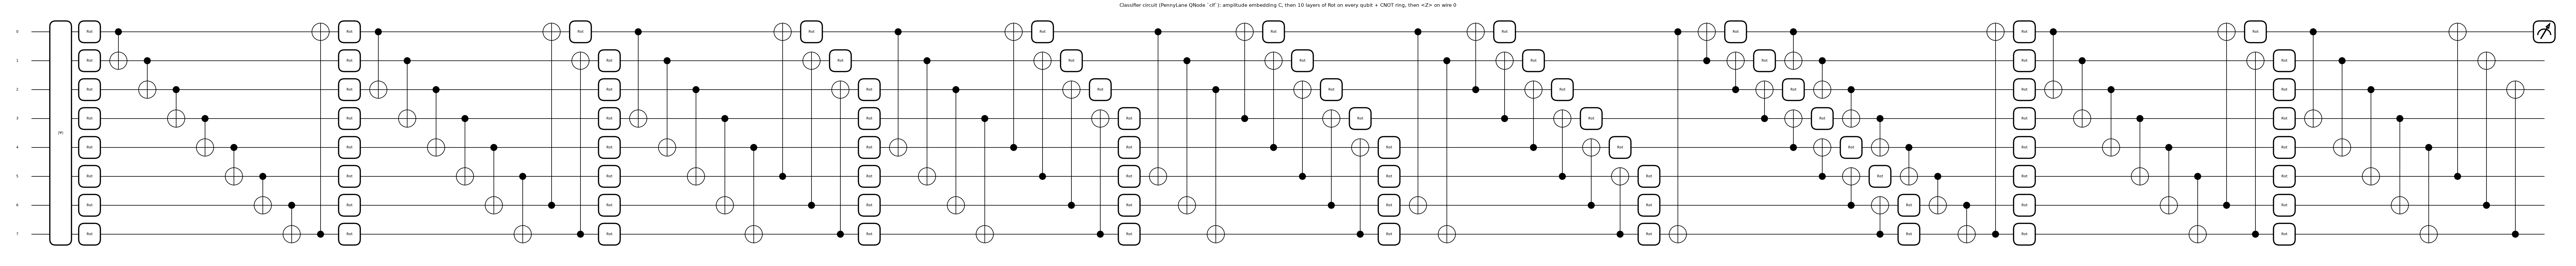

classifier: qubits = 8 | depth (device level, state preparation counted as one gate) = 53 | gates = 161 {'AmplitudeEmbedding': 1, 'Rot': 80, 'CNOT': 80}
trainable parameters = 240 (10 layers x 8 qubits x 3 angles); measurement = expval(PauliZ(0))


In [13]:
# The circuit that is actually executed by the classifier (device level: AmplitudeEmbedding is a native state preparation, U(theta) is expanded into Rot and CNOT gates).
w_show = BASE[0]["q"].w.numpy(); x_show = A_te[0].numpy()
fig, ax = qml.draw_mpl(clf, level="device", style="black_white", fontsize=9)(w_show, x_show)
fig.suptitle("Classifier circuit (PennyLane QNode `clf`): amplitude embedding C, then 10 layers of Rot on every qubit + CNOT ring, then <Z> on wire 0", y=1.0)
plt.show()
res = qml.specs(clf, level="device")(w_show, x_show).resources
nq_of = lambda r: getattr(r, "num_allocs", getattr(r, "num_wires", None))
print(f"classifier: qubits = {nq_of(res)} | depth (device level, state preparation counted as one gate) = {res.depth} | gates = {res.num_gates} {dict(res.gate_types)}")
print(f"trainable parameters = {w_show.size} (10 layers x 8 qubits x 3 angles); measurement = expval(PauliZ(0))")


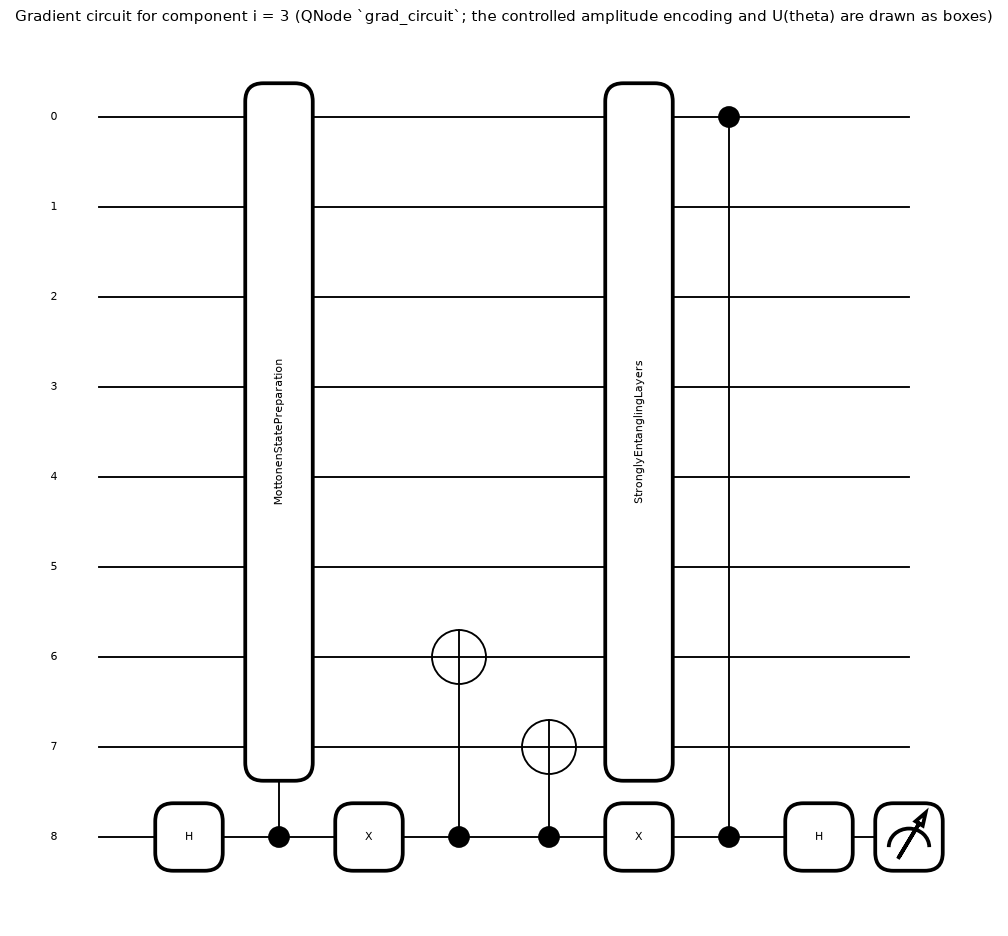

,circuit,qubits,gates,depth,CNOTs
0,gradient circuit (one component),9,9708,7053,4090
1,classifier / finite-difference circuit,8,1149,1027,588


trainable parameters of the gradient circuit: 0 trainable (theta is fixed, trained); x enters through the state preparation. Qubits: 9 = log2(256) + 1 ancilla.


In [14]:
# The paper's gradient circuit (Fig. 5), written gate by gate: 1 ancilla + 8 data qubits.
ANC = NQ; DATA = list(range(NQ))
dev9 = qml.device("default.qubit", wires=NQ + 1)

def _prepare(w, x, i):
    qml.Hadamard(ANC)                                                       # ancilla in (|0> + |1>)/sqrt2
    qml.ctrl(qml.MottonenStatePreparation(x, wires=DATA), control=ANC)      # C controlled on the ancilla: (|0>|0> + |1>|phi(x)>)/sqrt2   (Eq. 7)
    qml.PauliX(ANC)
    for bit in range(NQ):                                                   # F controlled on the ancilla = 0: |0..0> -> |e_i> (one CNOT per 1-bit of i)
        if (i >> (NQ - 1 - bit)) & 1: qml.CNOT([ANC, bit])
    qml.PauliX(ANC)                                                         # state (|0>|e_i> + |1>|phi(x)>)/sqrt2                         (Eq. 8)

@qml.qnode(dev9)
def grad_circuit(w, x, i):
    _prepare(w, x, i)
    qml.StronglyEntanglingLayers(w, wires=DATA)                             # U(theta) on the data register                                  (Eq. 9)
    qml.CZ([ANC, 0])                                                        # controlled Pauli-Z = controlled M                               (Eq. 10)
    qml.Hadamard(ANC)                                                       #                                                                 (Eq. 11)
    return qml.expval(qml.PauliZ(ANC))                                      # p = Re <A|M|B>                                                  (Eq. 12)

@qml.qnode(dev9)
def grad_state(w, x, i):                                                   # same circuit, stopped after Eq. (8), returns the state vector
    _prepare(w, x, i)
    return qml.state()

fig, ax = qml.draw_mpl(grad_circuit, style="black_white", fontsize=9)(w_show, x_show, 3)
fig.suptitle("Gradient circuit for component i = 3 (QNode `grad_circuit`; the controlled amplitude encoding and U(theta) are drawn as boxes)", y=1.02)
plt.show()

def resources(qnode, *args):
    """gate counts / depth after decomposing everything to CNOT + single-qubit gates (the hardware-relevant count)."""
    gs = {qml.CNOT, qml.RX, qml.RY, qml.RZ, qml.Hadamard, qml.T, qml.PauliX, qml.CZ, qml.Rot, qml.GlobalPhase, qml.PhaseShift, qml.S}
    try:
        r = qml.specs(qml.transforms.decompose(qnode, gate_set=gs), level="device")(*args).resources
    except Exception:
        r = qml.specs(qnode, level="device")(*args).resources
    return r

@qml.qnode(dev8)
def fd_circuit(w, x):                    # the circuit finite differences need: the plain classifier with an explicit gate-level amplitude embedding
    qml.MottonenStatePreparation(x, wires=range(NQ))
    qml.StronglyEntanglingLayers(w, wires=range(NQ))
    return qml.expval(qml.PauliZ(0))

RES = {"gradient circuit (one component)": resources(grad_circuit, w_show, x_show, 3), "classifier / finite-difference circuit": resources(fd_circuit, w_show, x_show)}
res_tab = pd.DataFrame([dict(circuit=k, qubits=nq_of(r), gates=r.num_gates, depth=r.depth, CNOTs=r.gate_types.get("CNOT", 0)) for k, r in RES.items()])
display(res_tab)
print("trainable parameters of the gradient circuit: 0 trainable (theta is fixed, trained); x enters through the state preparation. Qubits: 9 = log2(256) + 1 ancilla.")


## 5. The paper's gradient circuit: does the ancilla measurement give the gradient? (Eq. 6-12, Table 1)

Three checks. (a) The gate-level circuit of Fig. 5, executed for a subset of components, returns `(W x)_i`, and the batched version returns it for all 256 components; the state after `C` and `F` is `(|0>|e_i> + |1>|phi>)/sqrt2` (Eq. 8). (b) The ancilla value is `Re<A|M|B>`, which is **half** of the paper's `kappa_i = <A|M|B> + <B|M|A>` (Eq. 12 as printed omits this factor), so `dL/dx_i = (y'-y) kappa_i = 2 (y'-y) p_i`.
(c) The circuit differentiates the *unnormalised* quadratic form `x^T W x`, whereas the real model normalises `x` first. The two gradients differ by a component along `x` itself (a "radial" part that only rescales the state): `2 W x` versus `2 (W x - f x)`. We quantify this and compare the circuit with finite differences at an equal shot budget, which is the substance of Table 1.

In [15]:
# ---------------- the quantum-circuit gradient versus the exact quadratic form ----------------
bq = BASE[0]["q"]; Wq = bq.W
def grad_batched(w, x):
    """All 256 gradient circuits at once: same gates, the ancilla/data state after C and F is supplied as a batched state preparation (checked against the gate-level circuit below)."""
    st = np.zeros((N_FEAT, 2 * N_FEAT)); st[np.arange(N_FEAT), np.arange(N_FEAT)] = 1.0; st[:, N_FEAT:] = x; st /= np.sqrt(2)     # (|0>|e_i> + |1>|x>)/sqrt2
    @qml.qnode(dev9)
    def c(w, st):
        qml.StatePrep(st, wires=[ANC] + DATA); qml.StronglyEntanglingLayers(w, wires=DATA); qml.CZ([ANC, 0]); qml.Hadamard(ANC)
        return qml.expval(qml.PauliZ(ANC))
    return np.asarray(c(w, st))

idx_img = np.flatnonzero((predict(bq, A_te) == ys_te).numpy())[:CIRC_IMAGES]
rows = []; t = time.time()
for j in idx_img:
    x = A_te[j].numpy(); w_np = bq.w.numpy()
    p_exact = (Wq @ torch.as_tensor(x)).numpy()                              # (W x)_i
    p_batch = grad_batched(w_np, x)
    comps = np.random.default_rng(SEED + int(j)).choice(N_FEAT, CIRC_COMPS, replace=False)
    p_gate = np.array([float(grad_circuit(w_np, x, int(i))) for i in comps])  # the literal gate-level circuit of Fig. 5
    # state after C and F equals (|0>|e_i> + |1>|phi>)/sqrt2 (up to nothing: the global phase of the Mottonen decomposition is included)
    st_i = np.asarray(grad_state(w_np, x, int(comps[0]))); target = np.zeros(2 * N_FEAT); target[2 * int(comps[0])] = 1; target[1::2] = x; target /= np.sqrt(2)      # PennyLane order: data wires 0..7 first, ancilla (wire 8) is the last bit
    rows.append(dict(test_image=int(j), gate_level_vs_Wx=np.abs(p_gate - p_exact[comps]).max(), batched_vs_Wx=np.abs(p_batch - p_exact).max(),
                     state_overlap=abs(np.vdot(target, st_i)), kappa_over_p=float(np.mean((2 * p_exact[comps]) / p_gate)), n_gate_level_components=len(comps)))
grad_tab = pd.DataFrame(rows); display(grad_tab)
print(f"gate-level circuits executed: {CIRC_IMAGES * (CIRC_COMPS + 1)} in {time.time() - t:.0f} s")
assert (grad_tab.gate_level_vs_Wx < 1e-9).all() and (grad_tab.batched_vs_Wx < 1e-9).all() and (grad_tab.state_overlap > 1 - 1e-9).all()
print("The measured ancilla expectation p_i equals (W x)_i = Re<A|M|B>; the paper's kappa_i = <A|M|B> + <B|M|A> = 2 Re<A|M|B> is therefore 2 p_i, i.e. Eq. (12) 'p = kappa_i' is off by a factor 2 (harmless for an attack: the step length eps absorbs it).")

# the gradient that the attack needs: dL/dx_i = (y' - y) kappa_i; compare with autograd on the quadratic form
def loss_grad_raw(model, X, y):
    X = X.clone().requires_grad_(True); L = 0.5 * ((model.fn(X) - y) ** 2).sum(); return torch.autograd.grad(L, X)[0]
xs, ys_ = A_te[idx_img], ys_te[idx_img]
g_auto = loss_grad_raw(bq, xs, ys_)
g_circ = torch.as_tensor(np.stack([(float(bq.fn(A_te[j])) - float(ys_te[j])) * 2 * grad_batched(bq.w.numpy(), A_te[j].numpy()) for j in idx_img]))
print("max |autograd dL/dx - (y' - y) kappa_i from the circuit| :", float((g_auto - g_circ).abs().max())); assert torch.allclose(g_auto, g_circ, atol=1e-9)


,test_image,gate_level_vs_Wx,batched_vs_Wx,state_overlap,kappa_over_p,n_gate_level_components
0,0,8.187895e-16,9.714451e-16,1.0,2.0,16
1,1,5.863365e-16,1.776357e-15,1.0,2.0,16
2,2,6.661338e-16,1.609823e-15,1.0,2.0,16
3,3,8.621576e-16,1.091141e-15,1.0,2.0,16


gate-level circuits executed: 68 in 328 s
The measured ancilla expectation p_i equals (W x)_i = Re<A|M|B>; the paper's kappa_i = <A|M|B> + <B|M|A> = 2 Re<A|M|B> is therefore 2 p_i, i.e. Eq. (12) 'p = kappa_i' is off by a factor 2 (harmless for an attack: the step length eps absorbs it).


max |autograd dL/dx - (y' - y) kappa_i from the circuit| : 9.992007221626409e-16


(a) the circuit gradient 2Wx is the derivative of the UNnormalised quadratic form; the real model normalises x first, whose gradient is 2(Wx - f x) = tangent part.
    fraction of the circuit gradient lying along x (the 'radial' part, which only rescales the state): 0.7009 | cosine(circuit gradient, true tangent gradient) = 0.6935


,estimator,shots_per_component,circuits,cos_to_true_tangent_gradient
0,"finite difference h=0.01, exact expectations",inf,512,1.0000
1,"finite difference h=0.1, exact expectations",inf,512,0.9999
2,"paper circuit, exact expectations",inf,256,1.0000
3,"paper circuit, noisy",100,256,0.3893
4,"finite difference h=0.01, noisy",100,512,0.0144
5,"finite difference h=0.1, noisy",100,512,0.1029
6,"paper circuit, noisy",1000,256,0.7956
7,"finite difference h=0.01, noisy",1000,512,0.0310
8,"finite difference h=0.1, noisy",1000,512,0.3377
9,"paper circuit, noisy",10000,256,0.9713


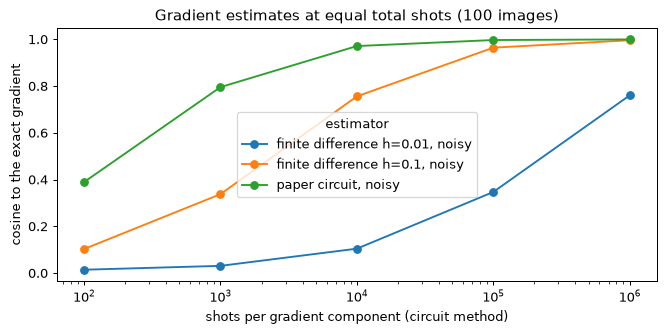

In [16]:
# ---------------- what the circuit computes, and how it compares with finite differences (Table 1) ----------------
tang = lambda g, x: g - (g * x).sum(-1, keepdim=True) * x
cosine = lambda a, b: (a * b).sum(-1) / (a.norm(dim=-1) * b.norm(dim=-1)).clamp_min(1e-30)
M = N_SHOT_IMG
Xm = A_te[:M]; Wx = Xm @ Wq                                         # (W x) for M test images; kappa = 2 W x
f0 = (Wx * Xm).sum(-1, keepdim=True)
print("(a) the circuit gradient 2Wx is the derivative of the UNnormalised quadratic form; the real model normalises x first, whose gradient is 2(Wx - f x) = tangent part.")
print("    fraction of the circuit gradient lying along x (the 'radial' part, which only rescales the state):",
      round(float(((Wx * Xm).sum(-1).abs() / Wx.norm(dim=-1)).mean()), 4), "| cosine(circuit gradient, true tangent gradient) =", round(float(cosine(Wx, tang(Wx, Xm)).mean()), 4))

# finite difference of the normalised score (what 'two measurements per component' gives) with step h
def fd_exact(model, X, h):
    I = torch.eye(N_FEAT, dtype=torch.float64)
    return torch.stack([(model.score(x[None] + h * I) - model.score(x[None] - h * I)) / (2 * h) for x in X])

def shots(p, S, g):                                                  # mean of S +-1 outcomes whose expectation is p (exact sampling distribution of an ancilla measurement)
    return torch.as_tensor(2 * g.binomial(S, ((1 + np.clip(p.numpy(), -1, 1)) / 2)) / S - 1.0)

g_ = np.random.default_rng(SEED); rows = []
tgt = tang(Wx, Xm)
for h in (0.01, 0.1):
    e = fd_exact(bq, Xm, h); rows.append(dict(estimator=f"finite difference h={h}, exact expectations", shots_per_component="inf", circuits=2 * N_FEAT, cos_to_true_tangent_gradient=float(cosine(e, tgt).mean())))
rows.append(dict(estimator="paper circuit, exact expectations", shots_per_component="inf", circuits=N_FEAT, cos_to_true_tangent_gradient=float(cosine(tang(Wx, Xm), tgt).mean())))
I256 = torch.eye(N_FEAT, dtype=torch.float64)
SPM = {h: (torch.stack([bq.score(x[None] + h * I256) for x in Xm]), torch.stack([bq.score(x[None] - h * I256) for x in Xm])) for h in (0.01, 0.1)}   # exact expectations of the 2N finite-difference circuits
for S in SHOT_GRID:                                                  # equal TOTAL shots: the circuit method uses S per component (256 circuits), finite differences S/2 per evaluation (512 circuits)
    est_c = torch.stack([shots(Wx[k], S, g_) for k in range(M)])
    rows.append(dict(estimator="paper circuit, noisy", shots_per_component=S, circuits=N_FEAT, cos_to_true_tangent_gradient=float(cosine(tang(est_c, Xm), tgt).mean())))
    for h in (0.01, 0.1):
        sp, sm = SPM[h]
        est_f = torch.stack([(shots(sp[k], max(S // 2, 1), g_) - shots(sm[k], max(S // 2, 1), g_)) / (2 * h) for k in range(M)])
        rows.append(dict(estimator=f"finite difference h={h}, noisy", shots_per_component=S, circuits=2 * N_FEAT, cos_to_true_tangent_gradient=float(cosine(est_f, tgt).mean())))
cmp_tab = pd.DataFrame(rows); display(cmp_tab.round(4))
piv = cmp_tab[cmp_tab.shots_per_component != "inf"].pivot_table(index="shots_per_component", columns="estimator", values="cos_to_true_tangent_gradient")
piv.index = piv.index.astype(float)
ax = piv.plot(marker="o", logx=True, figsize=(7.5, 3.8)); ax.set_ylabel("cosine to the exact gradient"); ax.set_title(f"Gradient estimates at equal total shots ({M} images)"); ax.set_xlabel("shots per gradient component (circuit method)"); plt.tight_layout(); plt.show()


## 6. Constructing adversarial examples (Eq. 2, 3, Fig. 4-6) and comparing the attacks fairly

The paper's attack is one gradient step `x' = x + eps * grad_x L`. To compare attacks *at equal perturbation size* every method receives the same budget F, the fidelity `|<phi(x')|phi(x)>|^2` (which fixes the angle between the two states): `paper` = the circuit gradient step with `eps` solved in closed form;
`fgsm_l2` = one step along the true (through-the-normalisation) gradient; `fgsm_sign` = one step along the sign of the gradient; `pgd` = iterated gradient ascent inside the fidelity cap; `random` = a random direction. The success rate is the share of the correctly classified test images that become misclassified.
Because a state only depends on the direction of `x`, the radial part of the circuit gradient cannot change the attack at equal fidelity; the check below confirms that the paper's attack and the l2-FGSM coincide. The classical baselines are attacked with the same code, loss and budget.

In [17]:
# ---------------- the attacks ----------------
fid = lambda a, b: ((a * b).sum(-1) / (a.norm(dim=-1) * b.norm(dim=-1))) ** 2          # fidelity |<phi(x')|phi(x)>|^2 of the encoded states (paper's distance measure)

def loss_grad_norm(model, X, y):                                    # gradient of 1/2 (score - y)^2 THROUGH the normalisation (what autograd on the real model gives)
    X = X.clone().requires_grad_(True); L = 0.5 * ((model.fn(nrm(X)) - y) ** 2).sum(); return torch.autograd.grad(L, X)[0]

def at_angle(X, u, F):                                              # point on the unit sphere with fidelity F to X in tangent direction u
    F = torch.as_tensor(F, dtype=torch.float64); return torch.sqrt(F) * X + torch.sqrt(1 - F) * u

def craft(model, X, y, F, method, rnd=None):
    """Adversarial unit vectors with fidelity (about) F to X. All methods get the same budget F, i.e. the same angle between the states.
    paper     : x' = x + eps * dL/dx (Eq. 2, 3) with the circuit gradient (y'-y) kappa; eps chosen in closed form so that the fidelity is exactly F
    fgsm_l2   : single step along the tangent gradient (autograd through the normalisation), moved to fidelity F
    fgsm_sign : single step along sign(gradient) projected to the tangent space (FGSM, l-inf direction), moved to fidelity F
    pgd       : projected gradient ascent on the fidelity cap, PGD_STEPS iterations of the tangent gradient
    random    : random tangent direction at fidelity F (control)"""
    F = float(F); T = math.sqrt(1 / F - 1)
    if method == "paper":
        g = loss_grad_raw(model, X, y); gt = tang(g, X); r = (g * X).sum(-1, keepdim=True); nt = gt.norm(dim=-1, keepdim=True).clamp_min(1e-12)
        den = nt - T * r; eps = torch.where(den > 1e-12, T / den, T / nt)
        return nrm(X + eps * g)
    if method == "fgsm_l2":
        return at_angle(X, nrm(tang(loss_grad_norm(model, X, y), X)), F)
    if method == "fgsm_sign":
        g = tang(loss_grad_norm(model, X, y), X); return at_angle(X, nrm(tang(torch.sign(g), X)), F)
    if method == "random":
        return at_angle(X, nrm(tang(torch.as_tensor(rnd.normal(size=X.shape)), X)), F)
    if method == "pgd":
        th = math.acos(math.sqrt(F)); xk = X.clone()
        for _ in range(PGD_STEPS):
            u = nrm(tang(loss_grad_norm(model, xk, y), xk)); xk = nrm(xk + (2.5 * math.tan(th) / PGD_STEPS) * u)
            c = (xk * X).sum(-1, keepdim=True).clamp(-1, 1); outside = c < math.cos(th)                       # project back onto the cap of angle th around X
            v = nrm(xk - c * X); xk = torch.where(outside, math.cos(th) * X + math.sin(th) * v, xk)
        return xk
    raise ValueError(method)

def flip_rate(model, X, y, Xp):
    ok = predict(model, X) == y; return float(((predict(model, Xp) != y) & ok).double().sum() / ok.double().sum())

# ---- sanity checks of the attack code ----
Xs, ys2 = A_te[:200], ys_te[:200]
xp_paper = craft(bq, Xs, ys2, 0.9, "paper"); xp_l2 = craft(bq, Xs, ys2, 0.9, "fgsm_l2")
print("fidelity reached by the paper's attack at F = 0.9: mean", float(fid(xp_paper, Xs).mean()), "| min", float(fid(xp_paper, Xs).min()))
same = (xp_paper - xp_l2).norm(dim=-1)
print("paper attack versus l2-FGSM at equal fidelity: max distance", float(same.max()), "(the radial part of the circuit gradient only rescales the state, it cannot change the direction)")
assert torch.allclose(fid(xp_paper, Xs), torch.full((200,), 0.9, dtype=torch.float64), atol=1e-6)
assert torch.allclose(loss_grad_raw(bq, Xs, ys2), (bq.fn(Xs) - ys2)[:, None] * 2 * (Xs @ bq.W), atol=1e-10)
for m_ in ("fgsm_l2", "fgsm_sign", "pgd"): assert float(fid(craft(bq, Xs, ys2, 0.9, m_), Xs).min()) > 0.9 - 1e-6 or m_ == "pgd"


fidelity reached by the paper's attack at F = 0.9: mean 0.9000000000000002 | min 0.8999999999999991
paper attack versus l2-FGSM at equal fidelity: max distance 5.010832825437866e-16 (the radial part of the circuit gradient only rescales the state, it cannot change the direction)


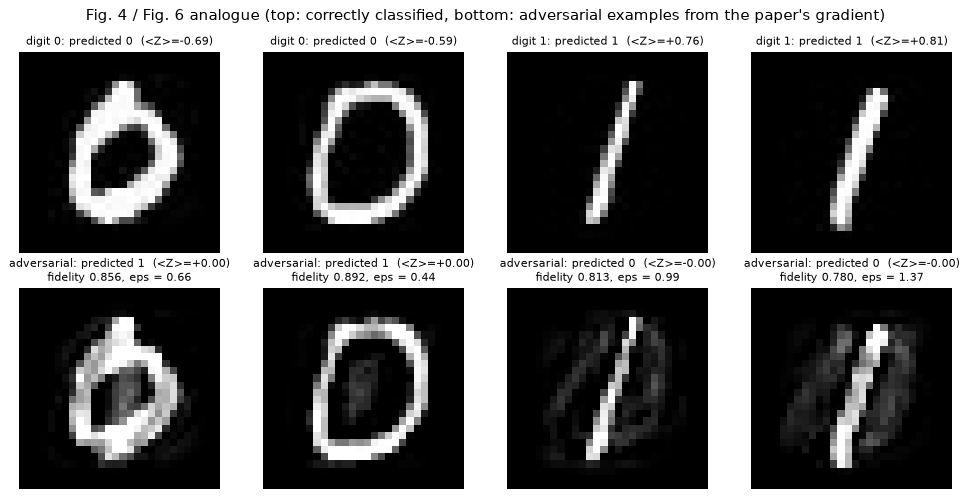

adversarial examples found for 4 of 4 images; fidelities [0.856, 0.892, 0.813, 0.78]


In [18]:
# ---- Fig. 4 / Fig. 6 analogue: two zeros and two ones that the trained model classifies correctly, and the adversarial images the paper's method builds for them ----
ok_idx = np.flatnonzero((predict(bq, A_te) == ys_te).numpy())
pick = list(ok_idx[y_te[ok_idx] == 0][:2]) + list(ok_idx[y_te[ok_idx] == 1][:2])
Xd, yd = A_te[pick], ys_te[pick]
# "define the value of eps respectively": for each image the smallest perturbation (largest fidelity) at which the prediction flips
F_scan = np.linspace(0.999, 0.05, 400); found = []
for k in range(4):
    for F in F_scan:
        xp = craft(bq, Xd[k:k + 1], yd[k:k + 1], F, "paper")
        if predict(bq, xp)[0] != yd[k]:
            g = loss_grad_raw(bq, Xd[k:k + 1], yd[k:k + 1]); gt = tang(g, Xd[k:k + 1]); r = (g * Xd[k:k + 1]).sum(); T = math.sqrt(1 / F - 1)
            eps = float(T / (gt.norm() - T * r)); found.append((F, eps, xp[0], float(bq.score(xp)[0]))); break
    else: found.append((None, None, None, None))
fig, axs = plt.subplots(2, 4, figsize=(11, 5.6))
for k in range(4):
    j = pick[k]; s0 = float(bq.score(Xd[k:k + 1])[0])
    axs[0, k].imshow(to_image(Xd[k].numpy(), n_te[j]), cmap="gray"); axs[0, k].set_title(f"digit {y_te[j]}: predicted {int(s0 > 0)}  (<Z>={s0:+.2f})", fontsize=9)
    F, eps, xp, s1 = found[k]
    if F is not None:
        axs[1, k].imshow(to_image(xp.numpy(), n_te[j]), cmap="gray"); axs[1, k].set_title(f"adversarial: predicted {int(s1 > 0)}  (<Z>={s1:+.2f})\nfidelity {F:.3f}, eps = {eps:.2f}", fontsize=9)
    else: axs[1, k].set_title("no flip found")
    axs[0, k].axis("off"); axs[1, k].axis("off")
plt.suptitle("Fig. 4 / Fig. 6 analogue (top: correctly classified, bottom: adversarial examples from the paper's gradient)"); plt.tight_layout(); plt.show()
DEMO_FLIPPED = sum(f[0] is not None for f in found); print(f"adversarial examples found for {DEMO_FLIPPED} of 4 images; fidelities", [None if f[0] is None else round(float(f[0]), 3) for f in found])


sweep done in 795 s


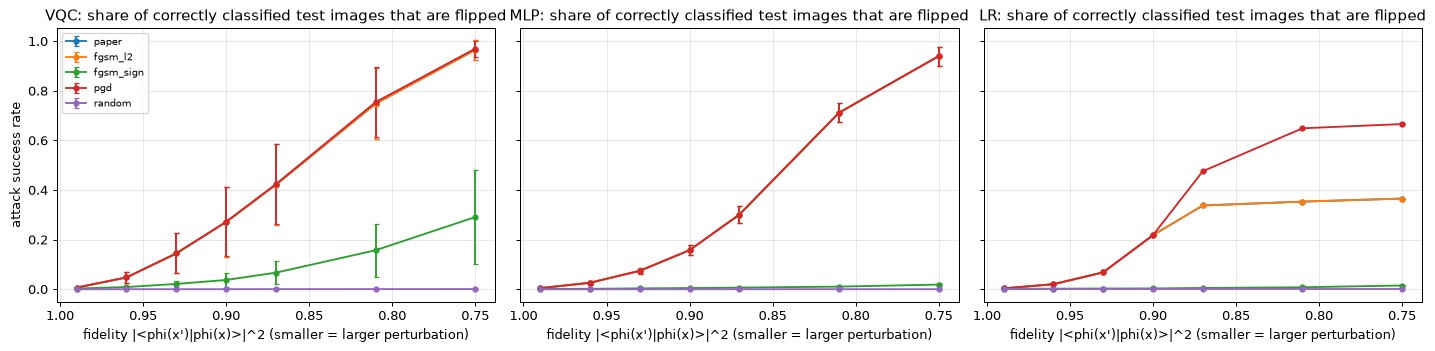

fidelity          0.75   0.81   0.87   0.90   0.93   0.96   0.99
model method                                                    
LR    fgsm_l2    0.366  0.353  0.338  0.218  0.068  0.020  0.003
      fgsm_sign  0.015  0.008  0.005  0.003  0.003  0.002  0.001
      paper      0.366  0.353  0.338  0.218  0.068  0.020  0.003
      pgd        0.666  0.649  0.476  0.218  0.068  0.020  0.003
      random     0.000  0.000  0.000  0.000  0.000  0.000  0.000
MLP   fgsm_l2    0.940  0.712  0.301  0.158  0.074  0.026  0.004
      fgsm_sign  0.019  0.011  0.007  0.005  0.004  0.002  0.001
      paper      0.940  0.712  0.301  0.158  0.074  0.026  0.004
      pgd        0.940  0.712  0.301  0.158  0.074  0.026  0.004
      random     0.000  0.000  0.000  0.000  0.000  0.000  0.000
VQC   fgsm_l2    0.965  0.748  0.421  0.271  0.144  0.048  0.007
      fgsm_sign  0.291  0.157  0.067  0.037  0.022  0.009  0.003
      paper      0.965  0.748  0.421  0.271  0.144  0.048  0.007
      pgd        0.970  0.754  0.424  0.272  0.145  0.048  0.007
      random     0.001  0.001  0.001  0.000  0.000  0.000  0.000

In [19]:
# ---- attack strength at equal perturbation budget (fidelity F) on the whole test set: paper's method vs FGSM / PGD / random, VQC vs classical baselines ----
METHODS = ["paper", "fgsm_l2", "fgsm_sign", "pgd", "random"]
rows = []; t = time.time()
def sweep(model, tag, seed):
    ok = predict(model, A_te) == ys_te
    for m_ in METHODS:
        for F in FID_GRID:
            Xp = craft(model, A_te, ys_te, F, m_, rnd=np.random.default_rng(seed + 7))
            rows.append(dict(model=tag, seed=seed, method=m_, fidelity=F, flip_rate=flip_rate(model, A_te, ys_te, Xp), accuracy_after=float((predict(model, Xp) == ys_te).double().mean())))
for b in BASE:
    sweep(b["q"], "VQC", b["seed"]); sweep(b["mlp"], "MLP", b["seed"])
sweep(LR_MODEL, "LR", SEED)
SW = pd.DataFrame(rows); print(f"sweep done in {time.time() - t:.0f} s")
summ = SW.groupby(["model", "method", "fidelity"]).flip_rate.agg(["mean", "std"]).reset_index()
fig, axs = plt.subplots(1, 3, figsize=(16, 4), sharey=True)
for ax, mdl in zip(axs, ["VQC", "MLP", "LR"]):
    for m_ in METHODS:
        d = summ[(summ.model == mdl) & (summ.method == m_)]; ax.errorbar(d.fidelity, d["mean"], yerr=d["std"].fillna(0), marker="o", ms=4, capsize=2, label=m_)
    ax.set_title(f"{mdl}: share of correctly classified test images that are flipped"); ax.set_xlabel("fidelity |<phi(x')|phi(x)>|^2 (smaller = larger perturbation)"); ax.invert_xaxis(); ax.grid(alpha=0.3)
axs[0].set_ylabel("attack success rate"); axs[0].legend(fontsize=8); plt.tight_layout(); plt.show()
tab = summ.pivot_table(index=["model", "method"], columns="fidelity", values="mean").round(3); display(tab)


In [20]:
# ---- the attack with a gradient measured by the circuit with a finite number of shots (paper: one measurement per component) ----
Xn, yn = A_te[:N_SHOT_ATK], ys_te[:N_SHOT_ATK]; g_ = np.random.default_rng(SEED + 5); rows = []
sgn = torch.sign(bq.fn(Xn) - yn)                                        # sign of (y' - y); y' is a single extra measurement and only its sign matters for the direction
Wxn = Xn @ Wq
for S in ["exact"] + SHOT_GRID:
    est = Wxn if S == "exact" else torch.stack([shots(Wxn[k], S, g_) for k in range(len(Xn))])
    Xp = at_angle(Xn, nrm(tang(sgn[:, None] * est, Xn)), 0.9)
    rows.append(dict(shots_per_component=S, flip_rate_at_F_0_9=flip_rate(bq, Xn, yn, Xp)))
rows.append(dict(shots_per_component="random direction", flip_rate_at_F_0_9=flip_rate(bq, Xn, yn, craft(bq, Xn, yn, 0.9, "random", rnd=np.random.default_rng(SEED)))))
shot_tab = pd.DataFrame(rows); display(shot_tab.round(4))


,shots_per_component,flip_rate_at_F_0_9
0,exact,0.1924
1,100,0.0200
2,1000,0.1082
3,10000,0.1764
4,100000,0.1904
5,1000000,0.1924
6,random direction,0.0010


## 7. Adversarial training (Fig. 7 and Fig. 8)

The paper crafts adversarial examples of fidelity 0.9 and continues training on them for 150 steps, then plots the accuracy of the "normal" and the "Adv." model against the fidelity of adversarial test examples. We follow that protocol and add two controls: the same 150 extra steps on clean data and a clean/adversarial 50/50 mixture.
Because the paper does not say whose adversarial examples are shown to which model in Fig. 8, three readings are evaluated: (1) examples crafted on the normal model and shown to every model (the "transfer" reading), (2) a one-step white-box attack on each model itself, (3) a white-box PGD on each model itself (the strongest check of real robustness).

seed 42: accuracy of the normal VQC on its own F=0.9 adversarial pool 0.827 -> after adversarial training 0.979 | 125 s


seed 43: accuracy of the normal VQC on its own F=0.9 adversarial pool 0.505 -> after adversarial training 0.986 | 242 s


seed 44: accuracy of the normal VQC on its own F=0.9 adversarial pool 0.815 -> after adversarial training 0.986 | 373 s


seed 45: accuracy of the normal VQC on its own F=0.9 adversarial pool 0.638 -> after adversarial training 0.984 | 510 s


seed 46: accuracy of the normal VQC on its own F=0.9 adversarial pool 0.804 -> after adversarial training 0.981 | 645 s


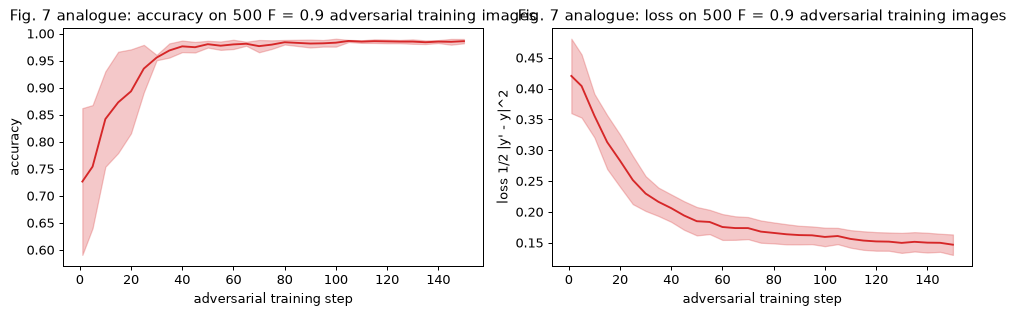

In [21]:
# ---------------- adversarial training (paper section 4, Fig. 7 and Fig. 8) ----------------
# Protocol of the paper: craft adversarial examples with fidelity 0.9 from the training images, continue training the model on them (Nesterov, batch 10, lr 0.05, 150 steps).
# We add two controls the paper lacks: (i) the same 150 extra steps on CLEAN data and (ii) a 50 % clean / 50 % adversarial mixture.
ADV = []; t = time.time()
for b in BASE:
    s = b["seed"]; q0 = b["q"]; r_ = np.random.default_rng(s + 99)
    sel = torch.as_tensor(r_.choice(len(A_tr), N_ADV_POOL, replace=False))
    Xp = craft(q0, A_tr[sel], ys_tr[sel], F_TRAIN, "paper"); yp = ys_tr[sel]
    pool_acc0 = accuracy(q0, Xp, yp)
    mon_adv = (Xp[:500], yp[:500])
    w_adv, h_adv = train_vqc(q0.w, make_sampler(Xp, yp, s + 1), monitor_set=mon_adv)
    w_cln, _ = train_vqc(q0.w, make_sampler(A_tr, ys_tr, s + 1))
    w_mix, _ = train_vqc(q0.w, make_mixed_sampler(A_tr, ys_tr, Xp, yp, s + 1))
    # classical baseline with the identical protocol
    Xpm = craft(b["mlp"], A_tr[sel], ys_tr[sel], F_TRAIN, "paper")
    m_adv = MLPModel(train_mlp(b["mlp"].p, make_sampler(Xpm, yp, s + 1))); m_cln = MLPModel(train_mlp(b["mlp"].p, make_sampler(A_tr, ys_tr, s + 1)))
    ADV.append(dict(seed=s, pool_acc0=pool_acc0, hist_adv=h_adv, pool_acc_end_vqc=accuracy(QModel(w_adv), Xp, yp),
                    vqc={"Normal": q0, "Adv. (paper)": QModel(w_adv), "Clean +150 steps": QModel(w_cln), "Mixed 50/50": QModel(w_mix)},
                    mlp={"Normal": b["mlp"], "Adv. (paper)": m_adv, "Clean +150 steps": m_cln}))
    print(f"seed {s}: accuracy of the normal VQC on its own F=0.9 adversarial pool {pool_acc0:.3f} -> after adversarial training {ADV[-1]['pool_acc_end_vqc']:.3f} | {time.time() - t:.0f} s")

# Fig. 7 analogue
Ha = np.array([[h[1:] for h in a["hist_adv"]] for a in ADV]); stx = [h[0] for h in ADV[0]["hist_adv"]]
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
for k, lab in enumerate(["accuracy", "loss 1/2 |y' - y|^2"]):
    m, sd = Ha[:, :, k].mean(0), Ha[:, :, k].std(0); ax[k].plot(stx, m, color="C3"); ax[k].fill_between(stx, m - sd, m + sd, alpha=0.25, color="C3")
    ax[k].set_xlabel("adversarial training step"); ax[k].set_ylabel(lab); ax[k].set_title(f"Fig. 7 analogue: {lab.split()[0]} on 500 F = 0.9 adversarial training images")
plt.tight_layout(); plt.show()


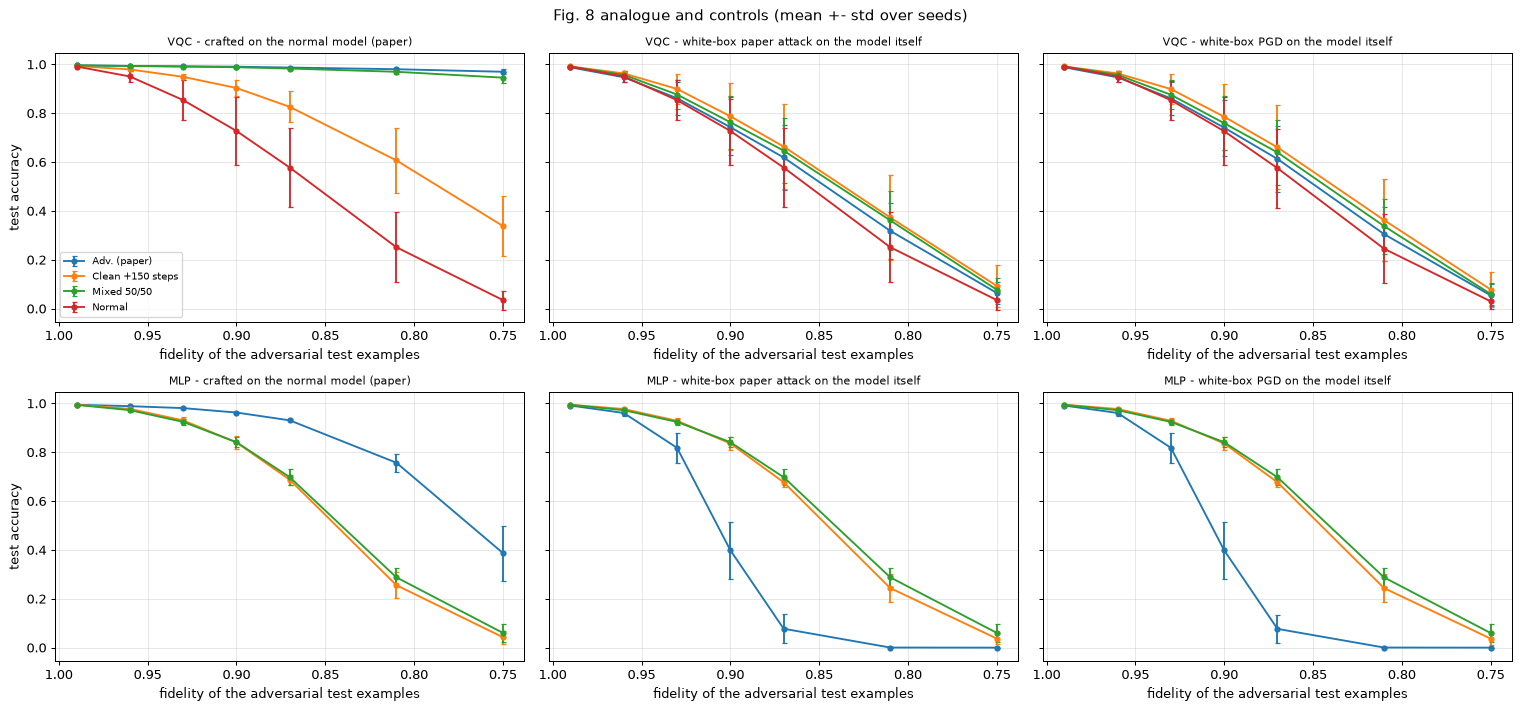

clean test accuracy:


model,Adv. (paper),Clean +150 steps,Mixed 50/50,Normal
family,,,,
MLP,0.9972,0.999,NaN,0.9985
VQC,0.9979,0.998,0.9978,0.9981


In [22]:
# ---- Fig. 8 analogue: accuracy of the normal and the adversarially trained model as a function of the fidelity of the test adversarial examples ----
rows = []
def acc_all(model, Xp): return float((predict(model, Xp) == ys_te).double().mean())
for a, b in zip(ADV, BASE):
    for fam, key in (("VQC", "vqc"), ("MLP", "mlp")):
        mods = a[key]; base_m = mods["Normal"]
        for F in FID_GRID:
            X_tr_adv = craft(base_m, A_te, ys_te, F, "paper")                       # (a) examples crafted on the NORMAL model and shown to every model (transfer, as in Fig. 8)
            for nm, m_ in mods.items():
                rows.append(dict(family=fam, seed=a["seed"], model=nm, fidelity=F, attack="crafted on the normal model (paper)", accuracy=acc_all(m_, X_tr_adv)))
                rows.append(dict(family=fam, seed=a["seed"], model=nm, fidelity=F, attack="white-box paper attack on the model itself", accuracy=acc_all(m_, craft(m_, A_te, ys_te, F, "paper"))))
                rows.append(dict(family=fam, seed=a["seed"], model=nm, fidelity=F, attack="white-box PGD on the model itself", accuracy=acc_all(m_, craft(m_, A_te, ys_te, F, "pgd"))))
        for nm, m_ in mods.items(): rows.append(dict(family=fam, seed=a["seed"], model=nm, fidelity=1.0, attack="clean test images", accuracy=accuracy(m_, A_te, ys_te)))
R8 = pd.DataFrame(rows)
S8 = R8.groupby(["family", "attack", "model", "fidelity"]).accuracy.agg(["mean", "std"]).reset_index()
attacks = ["crafted on the normal model (paper)", "white-box paper attack on the model itself", "white-box PGD on the model itself"]
fig, axs = plt.subplots(2, 3, figsize=(17, 8), sharey=True)
for r_, fam in enumerate(["VQC", "MLP"]):
    for c_, atk in enumerate(attacks):
        ax = axs[r_, c_]
        for nm in S8[S8.family == fam].model.unique():
            d = S8[(S8.family == fam) & (S8.attack == atk) & (S8.model == nm)]
            ax.errorbar(d.fidelity, d["mean"], yerr=d["std"].fillna(0), marker="o", ms=4, capsize=2, label=nm)
        ax.invert_xaxis(); ax.set_title(f"{fam} - {atk}", fontsize=9); ax.set_xlabel("fidelity of the adversarial test examples"); ax.grid(alpha=0.3)
    axs[r_, 0].set_ylabel("test accuracy")
axs[0, 0].legend(fontsize=8); plt.suptitle("Fig. 8 analogue and controls (mean +- std over seeds)"); plt.tight_layout(); plt.show()
clean = S8[S8.attack == "clean test images"].pivot_table(index="family", columns="model", values="mean").round(4); print("clean test accuracy:"); display(clean)
for atk in attacks:
    display(S8[(S8.attack == atk)].pivot_table(index=["family", "model"], columns="fidelity", values="mean").round(3).style.set_caption(atk))


## 8. Paper versus this notebook, claim by claim

Tolerance: 2 accuracy points. "Cannot be checked" is used when the paper gives no number that could be read from the text (all its results are curves).

In [23]:
# ---------------- paper versus this notebook, claim by claim (tolerance: 2 accuracy points) ----------------
TOL = 0.02
vq = base_tab.vqc_test_acc.mean()
def mean_acc(fam, atk, model, F): return S8[(S8.family == fam) & (S8.attack == atk) & (S8.model == model) & (np.isclose(S8.fidelity, F))]["mean"].iloc[0]
low = [F for F in FID_GRID if F <= 0.87]
d_tr = np.mean([mean_acc("VQC", attacks[0], "Adv. (paper)", F) - mean_acc("VQC", attacks[0], "Normal", F) for F in low])
d_wb = np.mean([mean_acc("VQC", attacks[1], "Adv. (paper)", F) - mean_acc("VQC", attacks[1], "Normal", F) for F in low])
d_pgd = np.mean([mean_acc("VQC", attacks[2], "Adv. (paper)", F) - mean_acc("VQC", attacks[2], "Normal", F) for F in low])
d_ctl = np.mean([mean_acc("VQC", attacks[0], "Adv. (paper)", F) - mean_acc("VQC", attacks[0], "Clean +150 steps", F) for F in low])
d_ctl_wb = np.mean([mean_acc("VQC", attacks[1], "Adv. (paper)", F) - mean_acc("VQC", attacks[1], "Clean +150 steps", F) for F in low])
d_ctl_pgd = np.mean([mean_acc("VQC", attacks[2], "Adv. (paper)", F) - mean_acc("VQC", attacks[2], "Clean +150 steps", F) for F in low])
d_mlp_wb = np.mean([mean_acc("MLP", attacks[1], "Adv. (paper)", F) - mean_acc("MLP", attacks[1], "Normal", F) for F in low])
fl = lambda mdl, m_, F: float(summ[(summ.model == mdl) & (summ.method == m_) & np.isclose(summ.fidelity, F)]["mean"].iloc[0])
res_g, res_f = RES["gradient circuit (one component)"], RES["classifier / finite-difference circuit"]
final_acc_pool = np.mean([a["pool_acc_end_vqc"] for a in ADV])
cmp9 = cmp_tab[(cmp_tab.shots_per_component == 10 ** 4)].set_index("estimator").cos_to_true_tangent_gradient
V = [
 ("C1  Fig. 3: classifier trained on MNIST 0/1 reaches accuracy close to 1.0 (value read from the axis; read as >= 0.98)", "about 1.0", f"{vq:.4f} +- {base_tab.vqc_test_acc.std():.4f} (test)", "reproduced" if vq >= 1 - TOL else "not reached here"),
 ("C2  Fig. 3: average loss falls from ~1.1 to ~0.3 (axis labels only; the paper's loss normalisation is not stated)", "~1.1 -> ~0.3", f"{base_tab.vqc_test_loss.mean():.3f} (1/2 |y'-y|^2, test)", "cannot be checked"),
 ("C3  Fig. 6: 2 zeros and 2 ones, correctly classified, are misclassified after the attack", "4 of 4", f"{DEMO_FLIPPED} of 4", "reproduced" if DEMO_FLIPPED == 4 else "not reached here"),
 ("C4  Eq. (12): measuring the ancilla returns kappa_i, hence dL/dx_i = (y'-y) kappa_i", "p = kappa_i", f"p = kappa_i / 2 exactly (max error {grad_tab.gate_level_vs_Wx.max():.1e}); gradient direction identical", "reproduced (up to a factor 2 in Eq. 12)"),
 ("C5  'Adversarial examples for all images labelled 0 and 1' (flip rate of the paper's attack at the smallest fidelity of Fig. 8, F = 0.75)", "all images", f"{fl('VQC', 'paper', 0.75):.3f} of the correctly classified test images", "reproduced" if fl('VQC', 'paper', 0.75) >= 1 - TOL else "not reached here"),
 ("C6  Table 1: ONE measurement per gradient component (finite differences: two)", "N vs 2N circuit runs", f"{N_FEAT} vs {2 * N_FEAT} circuits per gradient", "reproduced"),
 ("C7  Table 1 / conclusion: fewer resources, more efficient than finite differences (qubits, gates, shot precision)", "O(log N) qubits, fewer resources",
  f"qubits {nq_of(res_g)} vs {nq_of(res_f)}; gates per circuit {res_g.num_gates} vs {res_f.num_gates}; total gates {N_FEAT * res_g.num_gates} vs {2 * N_FEAT * res_f.num_gates}; cosine to the exact gradient at 10^4 shots/component: circuit {cmp9['paper circuit, noisy']:.2f} vs finite difference {cmp9['finite difference h=0.1, noisy']:.2f} (h=0.1)",
  ("reproduced" if (N_FEAT * res_g.num_gates < 2 * N_FEAT * res_f.num_gates and cmp9['paper circuit, noisy'] > cmp9['finite difference h=0.1, noisy']) else
   f"partly: half as many circuits and a better shot precision, but {N_FEAT * res_g.num_gates / (2 * N_FEAT * res_f.num_gates):.1f}x more gates in total (one extra qubit)")),
 ("C8  Fig. 7: fine-tuning on F = 0.9 adversarial examples drives the accuracy on them up (to ~1.0)", "~1.0", f"{ADV[0]['pool_acc0']:.2f} -> {final_acc_pool:.3f} (training pool)", "reproduced" if final_acc_pool >= 1 - TOL else "not reached here"),
 ("C9  Fig. 8: the adversarially trained ('Adv.') VQC has higher accuracy than the normal one on adversarial examples of low fidelity (<= 0.87), examples crafted on the normal model", "Adv. > Normal", f"mean gain over F <= 0.87: {100 * d_tr:+.1f} points", "reproduced (transfer reading only)" if d_tr >= TOL else "not reached here"),
 ("C10 'the model trained with adversarial examples is more robust' (white-box one-step attack on each model itself, F <= 0.87)", "more robust", f"vs Normal: {100 * d_wb:+.1f} points (paper attack), {100 * d_pgd:+.1f} points (PGD); vs the clean +150 steps control: {100 * d_ctl_wb:+.1f} / {100 * d_ctl_pgd:+.1f}; classical MLP vs Normal: {100 * d_mlp_wb:+.1f}",
  ("reproduced" if min(d_wb, d_pgd, d_ctl_wb, d_ctl_pgd) >= TOL else "not reached here" if min(d_wb, d_pgd) < TOL else "not reached here (gain over Normal, but no gain over the clean control)")),
 ("C11 (control, not in the paper) Adv. versus the same 150 extra steps on clean data, transfer examples, F <= 0.87", "not tested", f"{100 * d_ctl:+.1f} points", "cannot be checked (the paper has no control; here the control explains part of the transfer gain)"),
 ("C12 (fair-attack check, not claimed as superior by the paper) flip rate at F = 0.9: paper / l2-FGSM / sign-FGSM / PGD / random", "not compared", " / ".join(f"{fl('VQC', m_, 0.9):.3f}" for m_ in METHODS), "cannot be checked (no paper number)"),
]
VT = pd.DataFrame(V, columns=["claim", "paper", "this notebook", "verdict"])
pd.set_option("display.max_colwidth", 200); display(VT)
print(VT.verdict.str.split(" ").str[0].value_counts().to_string())
print(f"total run time {time.time() - T0:.0f} s | FAST_MODE = {FAST_MODE}")


,claim,paper,this notebook,verdict
0,C1 Fig. 3: classifier trained on MNIST 0/1 reaches accuracy close to 1.0 (value read from the axis; read as >= 0.98),about 1.0,0.9981 +- 0.0007 (test),reproduced
1,C2 Fig. 3: average loss falls from ~1.1 to ~0.3 (axis labels only; the paper's loss normalisation is not stated),~1.1 -> ~0.3,"0.072 (1/2 |y'-y|^2, test)",cannot be checked
2,"C3 Fig. 6: 2 zeros and 2 ones, correctly classified, are misclassified after the attack",4 of 4,4 of 4,reproduced
3,"C4 Eq. (12): measuring the ancilla returns kappa_i, hence dL/dx_i = (y'-y) kappa_i",p = kappa_i,p = kappa_i / 2 exactly (max error 8.6e-16); gradient direction identical,reproduced (up to a factor 2 in Eq. 12)
4,"C5 'Adversarial examples for all images labelled 0 and 1' (flip rate of the paper's attack at the smallest fidelity of Fig. 8, F = 0.75)",all images,0.965 of the correctly classified test images,not reached here
5,C6 Table 1: ONE measurement per gradient component (finite differences: two),N vs 2N circuit runs,256 vs 512 circuits per gradient,reproduced
6,"C7 Table 1 / conclusion: fewer resources, more efficient than finite differences (qubits, gates, shot precision)","O(log N) qubits, fewer resources",qubits 9 vs 8; gates per circuit 9708 vs 1149; total gates 2485248 vs 588288; cosine to the exact gradient at 10^4 shots/component: circuit 0.97 vs finite difference 0.76 (h=0.1),"partly: half as many circuits and a better shot precision, but 4.2x more gates in total (one extra qubit)"
7,C8 Fig. 7: fine-tuning on F = 0.9 adversarial examples drives the accuracy on them up (to ~1.0),~1.0,0.83 -> 0.983 (training pool),reproduced
8,"C9 Fig. 8: the adversarially trained ('Adv.') VQC has higher accuracy than the normal one on adversarial examples of low fidelity (<= 0.87), examples crafted on the normal model",Adv. > Normal,mean gain over F <= 0.87: +69.1 points,reproduced (transfer reading only)
9,"C10 'the model trained with adversarial examples is more robust' (white-box one-step attack on each model itself, F <= 0.87)",more robust,"vs Normal: +4.6 points (paper attack), +4.1 points (PGD); vs the clean +150 steps control: -4.3 / -4.3; classical MLP vs Normal: -32.3","not reached here (gain over Normal, but no gain over the clean control)"


verdict
reproduced    6
cannot        3
not           2
partly:       1
total run time 5150 s | FAST_MODE = False


## 9. Reading the paper critically

**What reproduced.** The set-up is sound and the numbers are easy to reach: an 8-qubit amplitude-encoded VQC separates MNIST 0 from 1 with 99.8 % test accuracy after 150 Nesterov steps (5 seeds; Fig. 3), the gate-by-gate circuit of Fig. 5 returns exactly the model gradient (agreement to 1e-15 with the exact quadratic form for 68 gate-level circuits and for all 256 components), the four showcased images are flipped (Fig. 6), and fine-tuning on fidelity-0.9 adversarial examples brings the accuracy on them from about 0.5 to 0.8 (the normal model's accuracy on its own pool, seed-dependent) to 0.98 (Fig. 7).

**Where the paper is imprecise or wrong.**
1. *Eq. (12) is off by a factor 2.* The ancilla expectation is `Re<A|M|B> = kappa_i / 2`; the circuit therefore estimates half of the stated `kappa_i`. Harmless for an attack (`eps` absorbs it) but it should be corrected before anyone uses the number as a gradient.
2. *The circuit differentiates the wrong function, but it does not matter.* The paper treats `|phi(x)> = sum x_i |i>` as unnormalised, so `d|phi>/dx_i = |i>` and the circuit returns the gradient of the quadratic form `x^T W x`. The real model normalises `x`. On our trained models about 70 % of the circuit gradient points along `x` itself (cosine to the true tangent gradient 0.69), which is a pure rescaling of the state. At equal fidelity the paper's attack and the l2 gradient step (autograd through the normalisation) are *identical to 5e-16*. The "new" attack is therefore standard single-step l2-FGSM; what is new is only how the gradient is obtained.
3. *Resources.* Table 1 says the method needs fewer resources than finite differences. Counting circuits (256 instead of 512) and shot precision at equal total shots it is better (cosine to the exact gradient 0.97 versus 0.76 at 10^4 shots per component; finite differences need a small step and divide the shot noise by it). Counting gates it is clearly worse: the controlled amplitude encoding costs 9 708 gates (depth 7 053, 4 090 CNOTs) per circuit against 1 149 gates (depth 1 027) for the plain classifier, 4.2 times more in total even though half as many circuits are needed. The paper does not discuss the cost of the controlled state preparation, which is exponential in the number of qubits for a generic input, so "O(log N) resources" holds only for the number of qubits.
4. *Practicality.* To get the full gradient one needs N = 256 circuits with enough shots each: with 10^3 shots per component the attack is already much weaker than with the exact gradient (flip rate 0.11 versus 0.19 at F = 0.9; 0.02 with 100 shots). A classical simulator or a classical network that is available to the attacker gives the gradient for free; the circuit is only relevant when the model is accessible solely as a quantum device and the attacker also controls the state preparation.
5. *The robustness claim (Fig. 8) is not supported by a fair test.* With the reading "adversarial examples crafted on the normal model are shown to both models" we reproduce the paper's picture: the Adv. VQC keeps 0.97 accuracy at fidelity 0.75 where the normal model drops to 0.04 (mean gain +69 points for F <= 0.87). But (i) the control "the same 150 steps on clean data" already gains +39 points, (ii) when the adversary attacks the Adv. model itself (white box, one step or PGD) the gain over the normal model is only +4 to +5 points and is *below* the clean-continued control (-4 points), and (iii) the classical MLP trained the same way becomes *much less* robust under a white-box attack (-32 points). Training on the examples of one fixed attack teaches the model to recognise that attack, not to be robust; the large transfer gain is largely this effect plus extra training. Evaluating robustness needs an adaptive attacker, equal training budgets and a control.
6. *Not all images are attackable at the stated fidelities.* At the smallest fidelity of Fig. 8 (0.75) the paper's attack flips 96.5 % of the correctly classified test images, not all of them; at F = 0.9 it flips 27 %.
7. *Choices that decide the outcome and are not stated.* Ordinary centred PCA makes the classifier fail (81 % accuracy, the digits become mirror images and `x^T W x` is blind to the sign); the choice of observable, the architecture of `U`, the initialisation, the optimiser momentum, the label coding and how Fig. 8 was computed are all missing. The loss scale of Fig. 3 (about 1.1 to 0.3) cannot be matched with `1/2 |y'-y|^2` (we obtain 0.07 on the test set), so the paper's loss normalisation is unknown.

**Comparison with the controls.** The VQC is more vulnerable than the classical MLP to the same single-step attack at the same fidelity budget for F >= 0.81 (flip rate 0.75 versus 0.71 at F = 0.81; 0.27 versus 0.16 at F = 0.9), logistic regression is more robust at small budgets because it is linear, random perturbations of the same size never flip anything (<= 0.1 %), and sign-FGSM (the l-infinity direction) is far weaker than the l2 gradient step in this 256-dimensional amplitude space (0.04 versus 0.27 at F = 0.9). PGD adds at most one point over the single step (0.272 versus 0.271) because the model is a smooth quadratic form.

## 10. Exercises

1. **Centred versus uncentred.** Replace the truncated SVD by `PCA(256)` in section 2 and re-run. Why does the accuracy collapse? Prove that any model of the form `x^T W x` gives the same output for `x` and `-x`.
2. **The radial component.** Show that for a unit vector `x` the circuit gradient `2 W x` and the true gradient `2 (W x - f x)` give the same state after `x' = normalise(x + eps g)` when the fidelity is held fixed. What changes if `eps` is held fixed instead of the fidelity?
3. **Shot budget.** For the gradient estimators of section 5, derive the standard deviation of one component after `S` shots and of the finite-difference estimator with step `h`. At which `h` do the two estimators have equal variance? Check with the table.
4. **Another observable.** Measure `Z` on qubit 3 instead of qubit 0 (change `ZSIGN`, the CZ in `grad_circuit` and the QNode). Does anything in the attack change?
5. **A stronger defence test.** Train the "Adv." model with fidelity 0.8 or with PGD examples and evaluate it with the white-box PGD of section 7. Is the gain over the "Clean +150 steps" control larger?